In [1]:
import pyranges as pr
import os
import gzip
import pandas as pd
import numpy as np
from scipy.sparse import dok_matrix, csr_matrix, coo_matrix

from hicexplorer import hicConvertFormat
from hicexplorer import hicSumMatrices

import hicmatrix.HiCMatrix as hm
from hicexplorer import utilities
import scipy.sparse as sp

import tempfile
import copy

import pyBigWig
import gzip
from sklearn.preprocessing import MinMaxScaler
import random

import networkx as nx

import community as community_louvain

from icecream import ic

from collections import OrderedDict

import matplotlib.pyplot as plt
%matplotlib inline
import umap.umap_ as umap
reducer = umap.UMAP()

import sklearn.decomposition as skd

import traceback
import timeit
import cProfile

import pyBigWig


In [719]:
# ROOT_PATH = '/Users/joachimwolff/data/epigenetic_graph_analyzer/'
ROOT_PATH = '/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer'

path_interactions_sample_1_1 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505208_Md_CapHiC_Merged_All-Tr_2ndBioRep_Chicago_output_washU_text.txt.gz")
path_interactions_sample_1_2 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505209_Md_CapHiC_3rdBioRep_Chicago_output_washU_text.txt.gz")

path_interactions_sample_2_1 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505210_PA2_CapHiC_2ndBioRep_Chicago_output_washU_text.txt.gz")
path_interactions_sample_2_2 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505211_PA2_E10.5wt_CapHiC_3rdBioRep_Tr1_Chicago_output_washU_text.txt.gz")

path_RNA_deseq = os.path.join(ROOT_PATH, "FMI_data/RNA_seq/Galaxy96-[DESeq2_result_file_on_data_88,_data_86,_and_others].tabular")
path_sample1_RNA_counts = os.path.join(ROOT_PATH, "FMI_data/RNA_seq/MD_E10.5_counts.tabular")
path_sample2_RNA_counts = os.path.join(ROOT_PATH, "FMI_data/RNA_seq/PA2_E10.5_counts.tabular")

rna_counts_list = [path_sample1_RNA_counts, path_sample2_RNA_counts]

path_sample1_histone_1 = [os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_MD_H3K4me2_R1.bigwig"), os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_MD_H3K4me2_R2.bigwig")]
path_sample1_histone_2 = [os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_MD_H3K27ac_R1.bigwig"), os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_MD_H3K27ac_R2.bigwig")]
path_sample1_histone_3 = [os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_MD_H3K27me3_R1.bigwig"), os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_MD_H3K27me3_R2.bigwig")]

chip_sample1_list = [path_sample1_histone_1, path_sample1_histone_2, path_sample1_histone_3]

path_sample2_histone_1 = [os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_PA2_H3K4me2_R1.bigwig"), os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_PA2_H3K4me2_R2.bigwig")]
path_sample2_histone_2 = [os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_PA2_H3K27ac_R1.bigwig"), os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_PA2_H3K27ac_R2.bigwig")]
path_sample2_histone_3 = [os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_PA2_H3K27me3_R1.bigwig"), os.path.join(ROOT_PATH, "FMI_data/chip_artifical_bw/E10.5_PA2_H3K27me3_R2.bigwig")]

chip_sample2_list = [path_sample2_histone_1, path_sample2_histone_2, path_sample2_histone_3]

chip_names_list = ['H3K4me2', 'H3K27ac', 'H3K27me3']

path_mm10_chromosome_size =  os.path.join(ROOT_PATH, "FMI_data/mm10.chrom.sizes.sort")
path_digest_mm10_hindIII =  os.path.join(ROOT_PATH, "FMI_data/hicup_digest/mm10_hindIII.txt")


path_promoter = os.path.join(ROOT_PATH, "FMI_data/mm10_promoter.bed")

path_output_bedpe_Md_rep1 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505208_Md_CapHiC_Merged_All-Tr_2ndBioRep_Chicago_output_bedpe.txt")
path_output_bedpe_MD_rep2 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505209_Md_CapHiC_3rdBioRep_Chicago_output_bedpe.txt")
path_output_bedpe_PA2_rep1 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505210_PA2_CapHiC_2ndBioRep_Chicago_output_bedpe.txt")
path_output_bedpe_PA2_rep2 = os.path.join(ROOT_PATH, "FMI_data/chic/GSE211904_RAW/GSM6505211_PA2_E10.5wt_CapHiC_3rdBioRep_Tr1_Chicago_output_bedpe.txt")

In [718]:
def washU_to_bedpe(path_input, path_output, compression='gzip'):
    pd_interactions = pd.read_table(path_input, header=None, sep='\t|,', compression=compression)
    pd_interactions['name'] = [str(x) for x in range(len(pd_interactions))]
    pd_interactions.to_csv(path_output, index=False, header=False, sep='\t', mode='a')

In [721]:
washU_to_bedpe(path_interactions_sample_1_1, path_output_bedpe_Md_rep1)
washU_to_bedpe(path_interactions_sample_1_2, path_output_bedpe_MD_rep2)
washU_to_bedpe(path_interactions_sample_2_1, path_output_bedpe_PA2_rep1)
washU_to_bedpe(path_interactions_sample_2_2, path_output_bedpe_PA2_rep2)


In [4]:
from multiprocessing import Process, Queue
import time
    

def process_interactions(interactions, hic_matrix, allow_inter_chr_interactions, pQueue):
    hic_lil_matrix = sp.lil_matrix(hic_matrix.matrix.shape)
    for chromosome_1, start_1, end_1, chromosome_2, start_2, end_2, value in zip(interactions[0], interactions[1], interactions[2], interactions[3], interactions[4], interactions[5], interactions[6]):
        if value == 0:
            continue
        if not allow_inter_chr_interactions:
            if chromosome_1 != chromosome_2:
                continue
        start_1 = start_1 + 1
        end_1 = end_1 - 1
        start_2 = start_2 + 1
        end_2 = end_2 - 1
        try:
            bin_id_1 = hic_matrix.getRegionBinRange(chromosome_1, start_1, end_1)
            bin_id_2 = hic_matrix.getRegionBinRange(chromosome_2, start_2, end_2)
            hic_lil_matrix[bin_id_1, bin_id_2] = value
        except Exception as exp:
            print(traceback.print_exc())
            ic(chromosome_1, start_1, end_1, value)
            ic(chromosome_2, start_2, end_2, value)
            pQueue.put('Fail: ' + str(exp) + traceback.format_exc())
            return
    
    pQueue.put(hic_lil_matrix)
    return

def run_parallel(interactions, hic_matrix, allow_inter_chr_interactions):
    num_processes = 8# multiprocessing.cpu_count()
    chunk_size = len(interactions) // num_processes
    queue = [None] * num_processes
    process = [None] * num_processes
    all_data_collected = False
    thread_done = [False] * num_processes
    interactions_thread = [None] * num_processes

    for i in range(num_processes):

        if i < num_processes - 1:
            interactions_thread[i] =  interactions.iloc[(i * chunk_size) : ((i + 1) * chunk_size)]
           
        else:
            interactions_thread[i] = interactions.iloc[(i * chunk_size):]
           

        queue[i] = Queue()
        process[i] = Process(target=process_interactions, kwargs=dict(
            interactions=interactions_thread[i],
            hic_matrix=hic_matrix,
            allow_inter_chr_interactions=allow_inter_chr_interactions,
            pQueue=queue[i]
        )
        )

        process[i].start()

    fail_flag = False
    fail_message = ''
    while not all_data_collected:
        for i in range(num_processes):
            if queue[i] is not None and not queue[i].empty():
                queue_data = queue[i].get()
                if (type(queue_data) == str) and ('Fail' in queue_data):
                    fail_flag = True
                    fail_message = queue_data
                else:
                    hic_matrix.matrix += queue_data

                queue[i] = None
                process[i].join()
                process[i].terminate()
                process[i] = None
                thread_done[i] = True
                interactions_thread[i] = None
        all_data_collected = True
        for thread in thread_done:
            if not thread:
                all_data_collected = False
        time.sleep(1)

    if fail_flag:
        return fail_message, None
    
    hic_matrix.matrix = hic_matrix.matrix.tocsr()
    return hic_matrix

def createMatrixTime(pd_interactions, cut_intervals, allow_inter_chr_interactions):
    hic_matrix_csr = sp.lil_matrix((len(cut_intervals), len(cut_intervals)))
    hic_matrix = hm.hiCMatrix()
    hic_matrix.setMatrix(hic_matrix_csr, cut_intervals)
    hic_matrix = run_parallel(pd_interactions, hic_matrix, allow_inter_chr_interactions)

    return hic_matrix

In [5]:
def createCutIntervals(chromosome_size_file, resolution):
    chrom_sizes = OrderedDict()
    size_genome = 0
    with open(chromosome_size_file, 'r') as file:
        file_ = True
        while file_:
            file_ = file.readline().strip()
            if file_ != '':
                line_split = file_.split('\t')
                chrom_sizes[line_split[0]] = int(line_split[1])
                size_genome += int(line_split[1])
    # chrom_sizes = list(chrom_sizes.items())

    cut_intervals = []
    if isinstance(resolution, int):
        for chromosome in chrom_sizes:
            for interval in range(0, chromosome[1], resolution):
                cut_intervals.append(tuple([chromosome[0], interval,
                                            min(chromosome[1], interval + resolution), 1.0]))
    else:
        restriction_cut_sites = pd.read_table(resolution, sep='\t')
        # ic(restriction_cut_sites)
        # restriction_cut_sites.columns = ['Chromosome', 'Start', 'End', '.', 'x', 'Strand']
        for row in restriction_cut_sites.iterrows():
            # ic(row, row[1])
            
            if row[1]['Chromosome'] in chrom_sizes:
                if int(row[1]['Start']) != int(row[1]['End']):
                    cut_intervals.append(tuple([str(row[1]['Chromosome']), int(row[1]['Start']), int(row[1]['End']), 1.0]))
    
    return cut_intervals

In [6]:
def importInteractionsFromWashUTime(list_of_washU_files, cut_intervals, allow_inter_chr_interactions=False, compression='gzip'):
    
    hic_matrix_list = []
    matrix_merged_csr = None
                
    for i, path_interactions in enumerate(list_of_washU_files):
        dtype_dict = {0:str, 1:int, 2:int, 3:str, 4:int, 5:int, 6:float}
        pd_interactions = pd.read_table(path_interactions, header=None, sep='\t|,', compression=compression, dtype=dtype_dict)
        
        hic_matrix = createMatrixTime(pd_interactions, cut_intervals, allow_inter_chr_interactions)
        hic_matrix_list.append(hic_matrix)

        # merge matrices
        if matrix_merged_csr is None:
            matrix_merged_csr = hic_matrix_list[0].matrix.tocsr()
        else:
            matrix_merged_csr += hic_matrix_list[i].matrix.tocsr()
    
    # compute an intersection matrix
    intersection_result_matrix = hic_matrix_list[0].matrix
            
    if len(hic_matrix_list) > 1:
        for hic_matrix in hic_matrix_list[1:]:
            intersection_matrix = intersection_result_matrix.multiply(hic_matrix.matrix).tocsr()
            intersection_matrix.eliminate_zeros()
            non_zero_ids = intersection_matrix.nonzero()
            data_merged_matrix = np.asarray(intersection_result_matrix[non_zero_ids]).flatten()
            data_hic_matrix = np.asarray(hic_matrix.matrix[non_zero_ids]).flatten()
            data_intersection = data_merged_matrix + data_hic_matrix
            intersection_result_matrix = csr_matrix((data_intersection, non_zero_ids),shape=intersection_result_matrix.shape)

    hic_matrix_list.append(matrix_merged_csr)
    hic_matrix_list.append(intersection_result_matrix / len(list_of_washU_files))

    return hic_matrix_list

In [7]:
cut_intervals = createCutIntervals(path_mm10_chromosome_size, resolution=path_digest_mm10_hindIII)

In [8]:
# chr6	52164817	52164877	Hoxa2_1

In [8]:
# interaction_matrices_sample_CD34 = importInteractionsFromWashU([path_interactions_CD34_rep1], path_hg19_chromosome_size, resolution=os.path.join(ROOT_PATH,  'Digest_Human_hg19_HindIII_header.txt'), compression=None)
interaction_matrices_sample_1 = importInteractionsFromWashUTime([path_interactions_sample_1_1, path_interactions_sample_1_2], cut_intervals, compression='gzip')

interaction_matrices_sample_2 = importInteractionsFromWashUTime([path_interactions_sample_2_1, path_interactions_sample_2_2], cut_intervals, compression='gzip')
# path_interactions_GM12878_rep1, 

In [370]:
def createSampleInteractionMatrix(path_promoter, chic_matrix):
    pyrange_promoter = pr.read_bed(path_promoter)

    matrix_list = []
    matrix_list_replicates = [[] for _ in range(len(chic_matrix[0:-2]))]
    bait_list = []
    for index, row in pyrange_promoter.as_df().iterrows():
        bait_location = row[['Chromosome', 'Start', 'End']]
        
        view_point_start = chic_matrix[0].getRegionBinRange(bait_location[0], bait_location[1], bait_location[1])
        if view_point_start is None:
            
            view_point_start = chic_matrix[0].getRegionBinRange(bait_location[0], bait_location[1]+1, bait_location[1]+1)
            
            if view_point_start is None:
                print(traceback.print_exc())
                ic(bait_location, row)
                break
        matrix_list.append(chic_matrix[-1][view_point_start[0], :])
        for i, matrix in enumerate(chic_matrix[0:-2]):
            matrix_list_replicates[i].append(matrix.matrix[view_point_start[0], :])
        bait_list.append([row[['Name']].str.split(',')[0][0], str(row['Chromosome']) + ":" + str(row['Start']) + "-"+ str(row['End'])])

    # Assuming you have a list of CSR matrices: matrix_list
    sample_matrix = sp.vstack(matrix_list)
    for i, matrix in enumerate(chic_matrix[0:-2]):
        matrix_list_replicates[i] = sp.vstack(matrix_list_replicates[i])
    return sample_matrix, bait_list, matrix_list_replicates

In [371]:
sample_matrix_sample_1, bait_list_sample_1, matrix_list_replicates_sample_1 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_1)
sample_matrix_sample_2, bait_list_sample_2, matrix_list_replicates_sample_2 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_2)

ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 261, in getRegionBinRange
    startbin = sorted(self.interval_trees[chrname][startpos:startpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 261, in getRegionBinRange
    startbin = sorted(self.interval_trees[chrname][startpos:startpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 261, in getRegionBinRange
    startbin = sorted(self.interval_trees[chrname][startpos:startpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix

In [372]:
matrix_list_replicates_sample_1

[<25111x851636 sparse matrix of type '<class 'numpy.float64'>'
 	with 166265 stored elements in Compressed Sparse Row format>,
 <25111x851636 sparse matrix of type '<class 'numpy.float64'>'
 	with 173370 stored elements in Compressed Sparse Row format>]

In [13]:
bait_list_sample_1_df = pd.DataFrame(bait_list_sample_1, columns=['Name', "Position"])
bait_list_sample_1_df[bait_list_sample_1_df["Name"].str.contains("Hoxa")]


,Name,Position
8138,Hoxaas2_1,chr6:52165656-52165716
8140,Hoxaas3_1,chr6:52175157-52175217
8141,Hoxaas3_2,chr6:52201170-52201230
8142,Hoxa11os_1,chr6:52245114-52245174
8143,Hoxa11os_2,chr6:52245954-52246014
8766,Hoxa1_1,chr6:52158218-52158278
8767,Hoxa2_1,chr6:52164817-52164877
8768,Hoxa4_1,chr6:52191691-52191751
8769,Hoxa6_1,chr6:52208661-52208721
8770,Hoxa9_1,chr6:52226176-52226236


In [14]:
bait_list_sample_2_df = pd.DataFrame(bait_list_sample_2, columns=['Name', "Position"])
bait_list_sample_2_df[bait_list_sample_2_df["Name"].str.contains("Hoxa")]

,Name,Position
8138,Hoxaas2_1,chr6:52165656-52165716
8140,Hoxaas3_1,chr6:52175157-52175217
8141,Hoxaas3_2,chr6:52201170-52201230
8142,Hoxa11os_1,chr6:52245114-52245174
8143,Hoxa11os_2,chr6:52245954-52246014
8766,Hoxa1_1,chr6:52158218-52158278
8767,Hoxa2_1,chr6:52164817-52164877
8768,Hoxa4_1,chr6:52191691-52191751
8769,Hoxa6_1,chr6:52208661-52208721
8770,Hoxa9_1,chr6:52226176-52226236


In [15]:
promoters = pr.read_bed(path_promoter)

In [16]:
promoters

,Chromosome,Start,End,Name,Score,Strand,ThickStart,ThickEnd
0,chr1,4807845,4807905,Lypla1_1,900,+,4807894,4807905
1,chr1,4857741,4857801,Tcea1_1,900,+,4857790,4857801
2,chr1,5083079,5083139,Atp6v1h_1,900,+,5083128,5083139
3,chr1,5588420,5588480,Oprk1_1,900,+,5588469,5588480
4,chr1,6214614,6214674,Rb1cc1_1,900,+,6214663,6214674
...,...,...,...,...,...,...,...,...
25106,chrY,1459766,1459826,Usp9y_1,900,-,1459766,1459777
25107,chrY,2170384,2170444,Zfy2_1,900,-,2170384,2170395
25108,chrY,3410158,3410218,Rbmy_1,900,-,3410158,3410169
25109,chrY,89713277,89713337,FJ541083_1,900,-,89713277,89713288


In [17]:
promoters.df[promoters.df['Name'] == 'CBX3-001,CBX3-002,CBX3-004,CBX3-003']

,Chromosome,Start,End,Name,Score,Strand,ThickStart,ThickEnd


In [395]:
def createGraphAndFindCommunities(sample_matrix, matrix_list_replicates, bait_list, path_output_graphml, cut_intervals, RNA_counts, ChIP_bigwig_files, threshold=5.0):
    G = nx.Graph()
    number_of_samples = sample_matrix.shape[0]
    bait_ids, OE_ids = sample_matrix.nonzero()
    # threshold_elements_list = []
    for i, (bait, OE) in enumerate(zip(bait_ids, OE_ids)):
        if sample_matrix.data[i] < threshold:
            # threshold_elements_list.append(bait)
            continue
        if (bait != OE):
            G.add_weighted_edges_from([(bait, OE+number_of_samples, sample_matrix.data[i])])
            G.nodes[OE + number_of_samples]['colorType'] = "orange"
            G.nodes[OE + number_of_samples]['position'] = cut_intervals[OE][0] + ":" + str(cut_intervals[OE][1]) + "-" +  str(cut_intervals[OE][2])
            for i, matrix_replicate in enumerate(matrix_list_replicates):
                # ic()  G[edge[0]][edge[1]]['log2FC']
                if 'replicate_weight' not in G[bait][OE+number_of_samples]:
                    G[bait][OE+number_of_samples]['replicate_weight'] = {}
                
                G[bait][OE+number_of_samples]["replicate_weight"][i] = matrix_replicate[bait, OE]
   
    if ChIP_bigwig_files is not None:

        for protein in ChIP_bigwig_files:
            for i, bigwig_file in enumerate(protein[1]):
                bw = pyBigWig.open(bigwig_file)

                for bait, OE in zip(bait_ids, OE_ids):

                    if (OE + number_of_samples) in G.nodes:
                        if 'protein' not in G.nodes[OE + number_of_samples]:
                            G.nodes[OE + number_of_samples]['protein'] = {}
                        try:
                            data = getDataFromBigWig(bw, cut_intervals[OE][0], cut_intervals[OE][1], cut_intervals[OE][2])
                            if protein[0] not in G.nodes[OE + number_of_samples]['protein']:
                                G.nodes[OE + number_of_samples]['protein'][protein[0]] = {} 
                            G.nodes[OE + number_of_samples]['protein'][protein[0]][i] = data
                        except Exception as exp:
                            ic("Chip Foo_1: " + str(exp))
                            ic(cut_intervals[OE])
                            ic(data)
                            pass
                bw.close()
            
    print("bait in bait_ids")
    for bait in bait_ids:
        # if bait in threshold_elements_list:
        #     continue
        if bait in G.nodes:
            G.nodes[bait]['name'] = bait_list[bait][0]
            G.nodes[bait]['colorType'] = "green"
            G.nodes[bait]['position'] = bait_list[bait][1]
            if RNA_counts is not None:
                # ic('Adding RNA')
                try:
                    data = RNA_counts[bait_list[bait][0].split('_')[0]]
                    G.nodes[bait]['RNA count'] = {}
                    # ic(data)
                    for i, replicate in enumerate(data):
                        # ic('RNA replicate add')
                        G.nodes[bait]['RNA count'][i] = data[replicate]
                except Exception as exp:
                    # ic(exp)
                    pass
    if ChIP_bigwig_files is not None:
        for protein in ChIP_bigwig_files:
            for i, bigwig_file in enumerate(protein[1]):
                bw = pyBigWig.open(bigwig_file)

                for bait in bait_ids:
                    if bait in G.nodes:
                        chrom = bait_list[bait][1].split(':')[0]
                        start = int(bait_list[bait][1].split(':')[1].split('-')[0])
                        end = int(bait_list[bait][1].split(':')[1].split('-')[1])

                        if 'protein' not in G.nodes[bait]:
                            G.nodes[bait]['protein'] = {}
                        if start < end:
                            try:
                                data = getDataFromBigWig(bw, chrom, start, end)
                                if protein[0] not in G.nodes[bait]['protein']:
                                    G.nodes[bait]['protein'][protein[0]] = {}
                                G.nodes[bait]['protein'][protein[0]][i] = data
                            except Exception as exp:
                                # ic(exp)
                                pass
                bw.close()
        

    print("partiion creating")

    # partition = community_louvain.best_partition(G)
    partition_list = nx.community.louvain_communities(G, seed=42)

    print("enumerate partion creating")

    gene_name_to_partition_mapping = {}
    for partition_id, partition in enumerate(partition_list):
        for node in partition:
            G.nodes[node]['partition'] = partition_id
            if "name" in G.nodes[node]:
                gene_name_to_partition_mapping[G.nodes[node]['name']] = partition_id

    # print("write graphml")

    # nx.write_graphml(G, path_output_graphml)

    return G, partition_list, gene_name_to_partition_mapping

In [145]:
chip_data_sample1 = []
for name, protein_paths in zip(chip_names_list, chip_sample1_list):
    chip_data_sample1.append([name, protein_paths])

chip_data_sample2 = []
for name, protein_paths in zip(chip_names_list, chip_sample2_list):
    chip_data_sample2.append([name, protein_paths])

In [147]:
chip_data_sample2


[['H3K4me2',
  ['/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/chip_artifical_bw/E10.5_PA2_H3K4me2_R1.bigwig',
   '/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/chip_artifical_bw/E10.5_PA2_H3K4me2_R2.bigwig']],
 ['H3K27ac',
  ['/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/chip_artifical_bw/E10.5_PA2_H3K27ac_R1.bigwig',
   '/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/chip_artifical_bw/E10.5_PA2_H3K27ac_R2.bigwig']],
 ['H3K27me3',
  ['/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/chip_artifical_bw/E10.5_PA2_H3K27me3_R1.bigwig',
   '/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/FMI_data/chip_artifical_bw/E10.5_PA2_H3K27me3_R2.bigwig']]]

In [152]:
def getDataFromBigWig(bigwig_file, chromosome, start, end):
    
    # data = []
    data = bigwig_file.values(chromosome, start, end, numpy=True)
    value = 0
    if len(data) > 0:
        mask = np.isnan(data)
        filtered_data = data[~mask]
        data = filtered_data
        if len(data) > 0:
            value = data.max()
    return value

In [177]:
sample1_rna_counts = pd.read_table(path_sample1_RNA_counts, sep='\t', index_col='key', skiprows=0)
sample2_rna_counts = pd.read_table(path_sample2_RNA_counts, sep='\t', index_col='key', skiprows=0)
sample1_rna_counts_dict = sample1_rna_counts.to_dict(orient='index')
sample2_rna_counts_dict = sample2_rna_counts.to_dict(orient='index')
# gm12878_rna_dictionary = gm12878_rna_counts.set_index(0)[1:].to_dict(orient='index')


In [186]:
data = sample2_rna_counts_dict['Hoxa2']
data
for foo in data:
    print(data[foo])

2635
2836
2438


In [167]:
sample1_rna_counts.to_dict(orient='index')

{'0610005C13Rik': {'dataset_b7cedc1f-65e9-4de3-9cee-06895af82171_V2': '6',
  'dataset_57acdbe6-6987-42f4-9888-36007d920d84_V2': '5',
  'dataset_45968efa-8e62-4536-aadf-b50f355804e7_V2': '6'},
 '0610009B22Rik': {'dataset_b7cedc1f-65e9-4de3-9cee-06895af82171_V2': '577',
  'dataset_57acdbe6-6987-42f4-9888-36007d920d84_V2': '579',
  'dataset_45968efa-8e62-4536-aadf-b50f355804e7_V2': '528'},
 '0610009E02Rik': {'dataset_b7cedc1f-65e9-4de3-9cee-06895af82171_V2': '6',
  'dataset_57acdbe6-6987-42f4-9888-36007d920d84_V2': '12',
  'dataset_45968efa-8e62-4536-aadf-b50f355804e7_V2': '5'},
 '0610009L18Rik': {'dataset_b7cedc1f-65e9-4de3-9cee-06895af82171_V2': '13',
  'dataset_57acdbe6-6987-42f4-9888-36007d920d84_V2': '7',
  'dataset_45968efa-8e62-4536-aadf-b50f355804e7_V2': '10'},
 '0610010F05Rik': {'dataset_b7cedc1f-65e9-4de3-9cee-06895af82171_V2': '1172',
  'dataset_57acdbe6-6987-42f4-9888-36007d920d84_V2': '1166',
  'dataset_45968efa-8e62-4536-aadf-b50f355804e7_V2': '1049'},
 '0610010K14Rik': {'da

In [396]:
graph_sample_1, partition_sample_1, gene_name_to_partition_mapping_sample_1 = createGraphAndFindCommunities(sample_matrix_sample_1, matrix_list_replicates_sample_1, bait_list_sample_1, os.path.join(ROOT_PATH, "Md_10.5.graphml"), cut_intervals=cut_intervals, RNA_counts=sample1_rna_counts_dict, ChIP_bigwig_files=chip_data_sample1, threshold=5.0)
graph_sample_2, partition_sample_2, gene_name_to_partition_mapping_sample_2 = createGraphAndFindCommunities(sample_matrix_sample_2, matrix_list_replicates_sample_2, bait_list_sample_2, os.path.join(ROOT_PATH, "PA2_10.5.graphml"), cut_intervals=cut_intervals, RNA_counts=sample2_rna_counts_dict, ChIP_bigwig_files=chip_data_sample2, threshold=5.0)

bait in bait_ids
partiion creating
enumerate partion creating
bait in bait_ids
partiion creating
enumerate partion creating


### Take result of Deseq2

- Consider the 100 top up and down regulated genes
- Write out their clusters with plotly

In [196]:
partition_sample_1[1222]

{8132,
 8133,
 8137,
 8138,
 8139,
 8140,
 8142,
 8143,
 8144,
 8145,
 8146,
 8147,
 8764,
 8765,
 8766,
 8767,
 8768,
 8769,
 8771,
 8773,
 8774,
 8775,
 8776,
 8777,
 642079,
 642080,
 642081,
 642082,
 642083,
 642084,
 642085,
 642086,
 642087,
 642088,
 642089,
 642142,
 642198,
 642309,
 642310,
 642352,
 642353,
 642354,
 642355,
 642356,
 642357,
 642358,
 642359,
 642360,
 642361,
 642410,
 642411,
 642412,
 642413,
 642417,
 642419,
 642423,
 642426,
 642430,
 642433,
 642434,
 642435,
 642436,
 642437,
 642443,
 642447,
 642450,
 642455,
 642456,
 642459,
 642460,
 642467,
 642549,
 642550,
 642551,
 642555,
 642560,
 642562,
 642579,
 642580,
 642646,
 642649,
 642650,
 642654,
 642663,
 642671,
 642672,
 642673,
 642674,
 652763}

'Cbx3_1'

In [216]:
import pandas as pd

# Load the file
df_deseq = pd.read_csv(os.path.join(ROOT_PATH, "FMI_data/RNA_seq/Galaxy96-[DESeq2_result_file_on_data_88,_data_86,_and_others].tabular"), sep='\t', names=['Gene', 'BaseMean', 'Log2FoldChange', 'LFCSE', 'Stat', 'PValue', 'PAdjust'])

# Display the dataframe
print(df_deseq)


                Gene     BaseMean  Log2FoldChange     LFCSE       Stat  \
0      3110099E03Rik  1512.783016        3.371268  0.091080  37.014179   
1               Tbx3  1703.799117       -3.122877  0.087573 -35.660318   
2              Satb2  3442.266758       -2.426331  0.068166 -35.594308   
3               Alx4  1380.619999       -4.157195  0.117720 -35.314347   
4             Cdkn1c  3906.737516       -2.097023  0.063319 -33.118481   
...              ...          ...             ...       ...        ...   
25234       Speer4f2     0.000000             NaN       NaN        NaN   
25235        Gm42517     0.191370       -0.960214  4.080473  -0.235319   
25236         Gm5565     0.000000             NaN       NaN        NaN   
25237      Btbd35f26     0.000000             NaN       NaN        NaN   
25238       Btbd35f6     0.000000             NaN       NaN        NaN   

              PValue        PAdjust  
0      6.773191e-300  1.019230e-295  
1      1.630536e-278  1.226815e-274

In [217]:
# get top 100 up and down genes
df_deseq_significant = df_deseq[df_deseq['PAdjust'] <= 0.05]
df_deseq_down = df_deseq_significant.sort_values(by='Log2FoldChange', ascending=True).head(100)
df_deseq_up = df_deseq_significant.sort_values(by='Log2FoldChange', ascending=False).head(100)

In [24]:
df_deseq_up

,Gene,BaseMean,Log2FoldChange,LFCSE,Stat,PValue,PAdjust
183,Hoxaas2,109.994250,10.230363,1.189876,8.597841,8.122950e-18,6.643161e-16
208,Hotairm1,73.346830,9.647215,1.195747,8.067940,7.149414e-16,5.147578e-14
13,Hoxa2,1314.130732,9.048572,0.379426,23.848029,1.061455e-125,1.140913e-122
242,Mybpc1,83.934598,8.874886,1.193774,7.434308,1.051165e-13,6.509438e-12
302,Hoxa3,22.456718,7.936845,1.231610,6.444282,1.161489e-10,5.779419e-09
...,...,...,...,...,...,...,...
14,Fzd4,1529.685646,1.793466,0.076046,23.583835,5.647368e-123,5.665440e-120
101,Tfap2a,276.389738,1.713895,0.146445,11.703335,1.225414e-31,1.807846e-29
851,Myo16,21.917903,1.700591,0.454496,3.741706,1.827749e-04,3.228166e-03
381,Clstn2,47.072404,1.690881,0.297706,5.679707,1.349255e-08,5.315076e-07


In [218]:
for up in df_deseq_up['Gene']:
        print(gene_name_to_partition_mapping_sample_1[up + '_1'])
        break

1222


In [219]:
def getCommunituesFromDESeq2Ranks(df_deseq_list, gene_name_to_partition_mapping, name_extension='_1'):
    cluster = {}
    for df_deseq in df_deseq_list:
        for gene_name in df_deseq['Gene']:
            partition_id = None
            if gene_name in gene_name_to_partition_mapping:
                partition_id = gene_name_to_partition_mapping[gene_name]
            elif gene_name + name_extension in gene_name_to_partition_mapping:
                partition_id = gene_name_to_partition_mapping[gene_name + name_extension]
            if partition_id:
                if partition_id not in cluster:
                    cluster[partition_id] = []
                data_rna = df_deseq[df_deseq['Gene'] == gene_name].values.tolist()
                if len(data_rna) != 0:
                    data_rna = data_rna[0]
                cluster[partition_id].append((gene_name, data_rna))
    return cluster

In [329]:
cluster_of_regulated_genes_sample_1 = getCommunituesFromDESeq2Ranks([df_deseq_up, df_deseq_down], gene_name_to_partition_mapping_sample_1, name_extension='_1')
cluster_of_regulated_genes_sample_2 = getCommunituesFromDESeq2Ranks([df_deseq_up, df_deseq_down], gene_name_to_partition_mapping_sample_2, name_extension='_1')

In [221]:
df_deseq_up[df_deseq_up['Gene'] == "Hoxa2"].values.tolist()


[['Hoxa2',
  1314.13073220341,
  9.04857181937984,
  0.379426395620414,
  23.8480293512111,
  1.06145549106154e-125,
  1.14091301639244e-122]]

In [274]:
def jaccardSimiliarityCommunities(community_1, community_2, number_of_baits):
    intersection_communities_nodes = []
    intersection_communities_jaccard = np.zeros((len(community_1), len(community_2)))
    intersection_communities_bait_jaccard = np.zeros((len(community_1), len(community_2)))
    for i in range(len(community_1)):
        intersection_communities_nodes.append({})
        for j in range(len(community_2)):
            intersection = community_1[i].intersection(community_2[j])

            if len(intersection) > 0:
                intersection_communities_nodes[i][j] = intersection
                intersection_communities_jaccard[i, j] = len(intersection) / len(community_1[i].union(community_2[j]))
                bait_intersection = {x for x in intersection if x <= number_of_baits}
                bait_community_1 = {x for x in community_1[i] if x <= number_of_baits}
                bait_community_2 = {x for x in community_2[j] if x <= number_of_baits}
                intersection_communities_bait_jaccard[i, j] = len(bait_intersection) / len(bait_community_1.union(bait_community_2))

    return intersection_communities_nodes, intersection_communities_jaccard, intersection_communities_bait_jaccard

In [330]:
jaccardSimilarity = jaccardSimiliarityCommunities(partition_sample_1, partition_sample_2, sample_matrix_sample_1.shape[0])

In [31]:
top_10_values = np.sort(jaccardSimilarity[2], axis=1)[:, ::-1][:, :5]

# Retrieve the indices of the columns for the top 10 values
top_10_indices = np.argsort(jaccardSimilarity[2], axis=1)[:, ::-1][:, :5]

In [32]:
partition_sample_1[1253]

{8323, 655213, 655214, 655216}

In [33]:
jaccardSimilarity[0][1222]

{1253: {652763},
 1328: {8133,
  8137,
  8138,
  8139,
  8140,
  8142,
  8143,
  8144,
  8145,
  8146,
  8147,
  8765,
  8766,
  8767,
  8768,
  8769,
  8771,
  8773,
  8774,
  8775,
  8776,
  642079,
  642080,
  642081,
  642082,
  642083,
  642084,
  642085,
  642086,
  642087,
  642088,
  642089,
  642198,
  642309,
  642310,
  642352,
  642353,
  642355,
  642356,
  642357,
  642358,
  642359,
  642360,
  642361,
  642410,
  642411,
  642413,
  642426,
  642433,
  642434,
  642435,
  642436,
  642437,
  642443,
  642447,
  642450,
  642455,
  642467,
  642549,
  642551,
  642555,
  642560,
  642562,
  642579,
  642580,
  642649,
  642650,
  642671,
  642672,
  642673},
 1329: {8777, 642456}}

In [38]:
top_10_indices[1222]


array([1328, 1329, 3676, 1219, 1230])

In [39]:
top_10_values[1222]

array([0.875     , 0.04166667, 0.        , 0.        , 0.        ])

In [40]:
jaccardSimilarity[0][1]

{0: {4, 25784}}

In [41]:
for x in jaccardSimilarity[0][1222]:
    print(x)

1253
1328
1329


In [205]:
cluster_of_regulated_genes_sample_1

{1222: [('Hoxaas2',
   ['Hoxaas2',
    109.994250467247,
    10.2303633446351,
    1.18987580215026,
    8.59784132608424,
    8.122950128942939e-18,
    6.64316051849638e-16]),
  ('Hotairm1',
   ['Hotairm1',
    73.3468297353744,
    9.64721528945183,
    1.19574702345019,
    8.06794004104302,
    7.14941396751236e-16,
    5.1475780566089e-14]),
  ('Hoxa2',
   ['Hoxa2',
    1314.13073220341,
    9.04857181937984,
    0.379426395620414,
    23.8480293512111,
    1.06145549106154e-125,
    1.14091301639244e-122]),
  ('Gm15050',
   ['Gm15050',
    8.42837265324665,
    6.52515908413468,
    1.30460291879352,
    5.00164378765079,
    5.68435474535636e-07,
    1.72804384258833e-05]),
  ('Hoxa1',
   ['Hoxa1',
    10.9640157981793,
    5.92010886273193,
    1.27457484250509,
    4.64477146834027,
    3.4045310900798e-06,
    8.89433747283347e-05])],
 2245: [('Hoxb2',
   ['Hoxb2',
    41.9382451031129,
    6.97937344435151,
    1.05339609169444,
    6.62559268956925,
    3.45857628353376e-1

In [43]:
graph_sample_1.nodes[8236]['weightFii'] = "sds"

In [44]:
graph_sample_1.nodes[8267]

KeyError: 8267

In [224]:
for edge in graph_sample_1.edges:
    if edge in graph_sample_2.edges:
        ic(graph_sample_1.get_edge_data(edge[0], edge[1])['weight'])
        break

ic| graph_sample_1.get_edge_data(edge[0], edge[1])['weight']: 8.64


In [225]:
def intersect(pyRangeObject, position):
    chromosome, position_start_end = position.split(":")
    start, end = position_start_end.split("-")
    query_data = {'Chromosome': [chromosome], 'Start': [int(start)], 'End': [int(end)]}
    query_df = pd.DataFrame(query_data)
    query = pr.PyRanges(query_df)

    return pyRangeObject.intersect(query)


In [586]:
# iterate throught a graph of networkx and copy the nodes. Check for the nodes if they have been existing in the other graph too. if yes, compute the log2Foldchange between them, if not, simply color them green if new in subgraph2, and purple if only in subgraph1
def mergeSubgraphs(pSubgraph_1, pSubgraph_2, RNA_genes, chip_data_list_pyrange):
    G = nx.Graph()
    G.add_nodes_from(copy.deepcopy(list(pSubgraph_1.nodes(data=True))))
    for node in pSubgraph_2.nodes:
        if node in G.nodes:
            degree_node_1 = pSubgraph_1.degree[node]
            degree_node_2 = pSubgraph_2.degree[node]

            G.nodes[node]["degree_log2FC"] = np.nan_to_num(np.log2(degree_node_2/degree_node_1))
            G.nodes[node]["degree_log2FC_binary"] = 1 if np.nan_to_num(np.log2(degree_node_2/degree_node_1)) >= 0 else -1

            # G.nodes[node]['protein']
            protein_dict_c1 = copy.deepcopy(pSubgraph_1.nodes[node]['protein'])
            protein_dict_c2 = copy.deepcopy(pSubgraph_2.nodes[node]['protein'])
            # pSubgraph_1.nodes[node]['protein'] = None
            # pSubgraph_2.nodes[node]['protein'] = None
            G.nodes[node]['protein'] = None
            G.nodes[node]['protein'] = {}
            G.nodes[node]['protein']['c1'] = protein_dict_c1
            G.nodes[node]['protein']['c2'] = protein_dict_c2

            # ic(G.nodes[node])
            # break
            if 'RNA count' in pSubgraph_1.nodes[node] and 'RNA count' in pSubgraph_2.nodes[node]:
                # ic(pSubgraph_1.nodes[node]['RNA count'])
                # ic(pSubgraph_2.nodes[node]['RNA count'])

                RNA_count_c1 = copy.deepcopy(pSubgraph_1.nodes[node]['RNA count'])
                RNA_count_c2 = copy.deepcopy(pSubgraph_2.nodes[node]['RNA count'])
                G.nodes[node]['RNA count'] = None
                G.nodes[node]['RNA count'] = {}
                G.nodes[node]['RNA count']['c1'] = RNA_count_c1
                G.nodes[node]['RNA count']['c2'] = RNA_count_c2




        else:
            # node is in condition 2 but not in condition 1
            G.add_nodes_from([(node, copy.deepcopy(pSubgraph_2.nodes[node]))])
            # G.nodes[node] = pSubgraph_2.nodes[node]
            G.nodes[node]["degree_log2FC"] = np.nan_to_num(np.log2(pSubgraph_2.degree[node]/1)) 
            G.nodes[node]["degree_log2FC_binary"] = 1 if np.nan_to_num(np.log2(pSubgraph_2.degree[node]/1)) >= 0 else -1
            # merge the protein data into c1 and c2 
            # copy protein data for condition 2
            protein_dict_c2 = copy.deepcopy(pSubgraph_2.nodes[node]['protein'])

            # copy protein data for condition 1 and set this to 0 because the node was not existing in condition 1
            protein_dict_c1 = copy.deepcopy(pSubgraph_2.nodes[node]['protein'])
            for protein in protein_dict_c1:
                for replicate in protein_dict_c1[protein]:
                    protein_dict_c1[protein][replicate] = 0
            
            G.nodes[node]['protein'] = None
            G.nodes[node]['protein'] = {}
            G.nodes[node]['protein']['c1'] = protein_dict_c1
            G.nodes[node]['protein']['c2'] = protein_dict_c2

            if 'RNA count' in pSubgraph_2.nodes[node]:
                # ic(pSubgraph_2.nodes[node]['RNA count'])

                RNA_count_c1 = copy.deepcopy(pSubgraph_2.nodes[node]['RNA count'])
                RNA_count_c2 = copy.deepcopy(pSubgraph_2.nodes[node]['RNA count'])

                # G.nodes[node]['RNA count'] = {}
                for replicate in RNA_count_c1:
                    RNA_count_c1[replicate] = 0
                G.nodes[node]['RNA count'] = None
                G.nodes[node]['RNA count'] = {}
                G.nodes[node]['RNA count']['c1'] = RNA_count_c1
                G.nodes[node]['RNA count']['c2'] = RNA_count_c2

        if 'position' in pSubgraph_2.nodes[node]:
            position = pSubgraph_2.nodes[node]['position']
            for chip_data, chip_name in chip_data_list_pyrange:
                intersections = intersect(chip_data, position)
                if len(intersections) > 0:
                    G.nodes[node][chip_name] = intersections.df.values[0][4]

        if 'name' in G.nodes[node]:
            for genes in RNA_genes:
                # ic(genes)
                # ic(G.nodes[node]['name'], genes)
                if G.nodes[node]['name'].split('_')[0]  == genes[0]:
                    G.nodes[node]['RNA log2FC'] = genes[1][2]
    for node in pSubgraph_1.nodes:
        if node not in pSubgraph_2.nodes:
            G.nodes[node]["degree_log2FC"] = np.nan_to_num(np.log2(1/pSubgraph_1.degree[node]))
            G.nodes[node]["degree_log2FC_binary"] = 1 if np.nan_to_num(np.log2(1/pSubgraph_1.degree[node])) >= 0 else -1

             
            # ic(pSubgraph_2.nodes[node]['protein'])
            # merge the protein data into c1 and c2 
            # copy protein data for condition 1
            protein_dict_c1 = copy.deepcopy(pSubgraph_1.nodes[node]['protein'])

            # copy protein data for condition 2 and set this to 0 because the node was not existing in condition 2
            protein_dict_c2 = copy.deepcopy(pSubgraph_1.nodes[node]['protein'])
            for protein in protein_dict_c2:
                for replicate in protein_dict_c2[protein]:
                    protein_dict_c2[protein][replicate] = 0
            
            G.nodes[node]['protein'] = None
            G.nodes[node]['protein'] = {}
            G.nodes[node]['protein']['c1'] = protein_dict_c1
            G.nodes[node]['protein']['c2'] = protein_dict_c2
            for protein in G.nodes[node]['protein']['c2']:
                for replicate in G.nodes[node]['protein']['c2'][protein]:
                    G.nodes[node]['protein']['c2'][protein][replicate] = 0

            if 'RNA count' in pSubgraph_1.nodes[node]:
                # ic(pSubgraph_1.nodes[node]['RNA count'])

                RNA_count_c1 = copy.deepcopy(pSubgraph_1.nodes[node]['RNA count'])
                RNA_count_c2 = copy.deepcopy(pSubgraph_1.nodes[node]['RNA count'])

                # G.nodes[node]['RNA count'] = {}
                for replicate in RNA_count_c2:
                    RNA_count_c2[replicate] = 0
                G.nodes[node]['RNA count'] = None
                G.nodes[node]['RNA count'] = {}
                G.nodes[node]['RNA count']['c1'] = RNA_count_c1
                G.nodes[node]['RNA count']['c2'] = RNA_count_c2

            if 'name' in G.nodes[node]:
                for genes in RNA_genes:
                    if G.nodes[node]['name'].split('_')[0] == genes[0]:
                        G.nodes[node]['RNA log2FC'] = genes[1][2]

            if 'position' in pSubgraph_1.nodes[node]:
                position = pSubgraph_1.nodes[node]['position']
                for chip_data, chip_name in chip_data_list_pyrange:
                    intersections = intersect(chip_data, position)
                    if len(intersections) > 0:
                        G.nodes[node][chip_name] = intersections.df.values[0][4]

    for edge in pSubgraph_1.edges:
        if edge in pSubgraph_2.edges:
            weight_1 = copy.deepcopy(pSubgraph_1.get_edge_data(edge[0], edge[1])['weight'])
            weight_2 = copy.deepcopy(pSubgraph_2.get_edge_data(edge[0], edge[1])['weight'])
            edge = (edge[0], edge[1], weight_2 / weight_1)
            G.add_weighted_edges_from([edge])
            G[edge[0]][edge[1]]['log2FC'] = np.log2(weight_2 / weight_1)
            G[edge[0]][edge[1]]['log2FC_binary'] = 1 if np.log2(weight_2 / weight_1) >= 0 else -1
            G[edge[0]][edge[1]]['weight'] = {}
            G[edge[0]][edge[1]]['weight']['c1'] = weight_1
            G[edge[0]][edge[1]]['weight']['c2'] = weight_2

            #G[bait][OE+number_of_samples]["replicate_weight"][i]
            weight_replicate_c1 = copy.deepcopy(pSubgraph_1.get_edge_data(edge[0], edge[1])['replicate_weight'])
            weight_replicate_c2 = copy.deepcopy(pSubgraph_2.get_edge_data(edge[0], edge[1])['replicate_weight'])
            G[edge[0]][edge[1]]['replicate_weight'] = {}

            G[edge[0]][edge[1]]['replicate_weight']['c1'] = weight_replicate_c1
            G[edge[0]][edge[1]]['replicate_weight']['c2'] = weight_replicate_c2

            # ic(pSubgraph_1.get_edge_data(edge[0], edge[1])['replicate_weight'])

        else:
            edge = (edge[0], edge[1], 1 / pSubgraph_1.get_edge_data(edge[0], edge[1])['weight'])
            G.add_weighted_edges_from([edge])
            G[edge[0]][edge[1]]['log2FC'] = np.log2(1 / pSubgraph_1.get_edge_data(edge[0], edge[1])['weight'])
            G[edge[0]][edge[1]]['log2FC_binary'] = 1 if np.log2(1 / pSubgraph_1.get_edge_data(edge[0], edge[1])['weight']) >= 0 else -1
            
            weight_1 = copy.deepcopy(pSubgraph_1.get_edge_data(edge[0], edge[1])['weight'])
            G[edge[0]][edge[1]]['weight'] = {}
            G[edge[0]][edge[1]]['weight']['c1'] = weight_1
            G[edge[0]][edge[1]]['weight']['c2'] = 0

            weight_replicate_c1 = copy.deepcopy(pSubgraph_1.get_edge_data(edge[0], edge[1])['replicate_weight'])
            weight_replicate_c2 = copy.deepcopy(pSubgraph_1.get_edge_data(edge[0], edge[1])['replicate_weight'])

            for replicate in weight_replicate_c2:
                weight_replicate_c2[replicate] = 0
            G[edge[0]][edge[1]]['replicate_weight'] = {}

            G[edge[0]][edge[1]]['replicate_weight']['c1'] = weight_replicate_c1
            G[edge[0]][edge[1]]['replicate_weight']['c2'] = weight_replicate_c2

    for edge in pSubgraph_2.edges:
        if edge not in pSubgraph_1.edges:
            edge = (edge[0], edge[1], pSubgraph_2.get_edge_data(edge[0], edge[1])['weight'] / 1)
            G.add_weighted_edges_from([edge])
            G[edge[0]][edge[1]]['log2FC'] = np.log2(pSubgraph_2.get_edge_data(edge[0], edge[1])['weight'] / 1)
            G[edge[0]][edge[1]]['log2FC_binary'] = 1 if np.log2(pSubgraph_2.get_edge_data(edge[0], edge[1])['weight'] / 1) >= 0 else -1
            weight_2 = copy.deepcopy(pSubgraph_2.get_edge_data(edge[0], edge[1])['weight'])
            G[edge[0]][edge[1]]['weight'] = {}
            G[edge[0]][edge[1]]['weight']['c1'] = 0
            G[edge[0]][edge[1]]['weight']['c2'] = weight_2

            weight_replicate_c1 = copy.deepcopy(pSubgraph_2.get_edge_data(edge[0], edge[1])['replicate_weight'])
            weight_replicate_c2 = copy.deepcopy(pSubgraph_2.get_edge_data(edge[0], edge[1])['replicate_weight'])

            for replicate in weight_replicate_c1:
                weight_replicate_c2[replicate] = 0
            G[edge[0]][edge[1]]['replicate_weight'] = {}
            G[edge[0]][edge[1]]['replicate_weight']['c1'] = weight_replicate_c1
            G[edge[0]][edge[1]]['replicate_weight']['c2'] = weight_replicate_c2


    return G



In [584]:
def writePlotlyGraphs(cluster_of_regulated_genes, output_path, graph_sample_1, partition_of_graph_sample_1, graph_sample_2, partition_of_graph_sample_2, jaccardSimilarityCommunities, sample_1_name_prefix, sample_2_name_prefix, chip_data_list_pyrange):
    analyse_result_df = None
    
    for partition_id, genes in cluster_of_regulated_genes.items():
        # Check if the path exists
        if not os.path.exists(os.path.join(output_path, str(partition_id))):
            # Create the path
            os.makedirs(os.path.join(output_path, str(partition_id)))
        writePlotlyGraph(partition_id, os.path.join(output_path, str(partition_id)), graph_sample_1.subgraph(partition_of_graph_sample_1[partition_id]), genes, sample_1_name_prefix)
        intersection = jaccardSimilarityCommunities[0][partition_id]

        for id in intersection:
            # writePlotlyGraph(id, os.path.join(output_path, str(partition_id)), graph_sample_2.subgraph(partition_of_graph_sample_2[id]), genes, sample_2_name_prefix)
            merged_graph = mergeSubgraphs(graph_sample_1.subgraph(partition_of_graph_sample_1[partition_id]), graph_sample_2.subgraph(partition_of_graph_sample_2[id]), genes, chip_data_list_pyrange)
            analyseMergedGraphResult, df_connected_nodes =  createSiginficantTestingTable(merged_graph, output_path, 3, chip_data_list_pyrange, partition_id, id)
            if analyse_result_df is None:
                analyse_result_df = analyseMergedGraphResult
            else:
                analyse_result_df = pd.concat([analyse_result_df, analyseMergedGraphResult], axis=0)
            # return analyseMergedGraphResult, df_connected_nodes
            # computeSignificanceRLM(df_connected_nodes)
            # writePlotlyGraphMerged(partition_id, id, os.path.join(output_path, str(partition_id)), merged_graph, genes, sample_1_name_prefix + '_' + sample_1_name_prefix)
            # writePlotlyGraphMergedPlotly(partition_id, id, os.path.join(output_path, str(partition_id)), merged_graph, genes, sample_1_name_prefix + '_' + sample_1_name_prefix)

            # print(analyseMergedGraphResult)

    if analyse_result_df is not None:
        analyse_result_df.to_csv(os.path.join(output_path, "results_merged.csv"))
    
    return analyse_result_df, df_connected_nodes


In [228]:
def normalize_and_color(nodes, attribute):
    values = [data[attribute] for _, data in nodes]
    norm_values = [np.nan_to_num((value - min(values)) / (max(values) - min(values))) for value in values]
    colors = px.colors.sequential.Plasma
    node_color = [colors[int(norm * (len(colors) - 1))] for norm in norm_values]
    return node_color



In [229]:
def writePlotlyGraphMerged(id_sample_1, id_sample_2, output_path, graph, genes_to_highlight, sample_name):
    # output_file(os.path.join(output_path, 'Merged_' + str(id_sample_1) + "_" + str(id_sample_2) + ".html"), title=sample_name)
    nx.write_graphml(graph, os.path.join(output_path, 'Merged_' + str(id_sample_1) + "_" + str(id_sample_2) + ".graphml"))

In [230]:
def writePlotlyGraphMergedPlotly(id_sample_1, id_sample_2, output_path, graph, genes_to_highlight, sample_name):
    G= graph
    pos = nx.spring_layout(graph)

    def create_trace(attribute, colorscale):
        node_color = normalize_and_color(G.nodes(data=True), attribute)
        node_trace = go.Scatter(
            x=[pos[node][0] for node in G],
            y=[pos[node][1] for node in G],
            text=[f"{G.nodes[node]['name'] if 'name' in G.nodes[node] else 'OE'} " for node in G],
            mode='markers+text',
            marker=dict(
                showscale=True,
                colorscale=colorscale,
                size=10,
                color=node_color,
                colorbar=dict(title=attribute.capitalize()),
                line_width=2),
            name=attribute)
        return node_trace

    # Traces for each attribute
    trace_score = create_trace('degree_log2FC', colorscale='RdBu_r')
    # trace_weight = create_trace('weight', colorscale='Turbo')

    # Edge trace
    edge_trace = go.Scatter(
        x=[],
        y=[],
        line=dict(width=0.5, color='#888'),
        hoverinfo='none',
        mode='lines')

    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace['x'] += tuple([x0, x1, None])
        edge_trace['y'] += tuple([y0, y1, None])

    # Create figure
    fig = go.Figure(data=[edge_trace, trace_score],  # Initially show 'score'
                    layout=go.Layout(
                        title=sample_name + ': Cluster ' + str(id_sample_1) + ' to ' + str(id_sample_2),
                        showlegend=False,
                        hovermode='closest',
                        margin=dict(b=0, l=0, r=0, t=0),
                        xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                        yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                        updatemenus=[dict(
                            buttons=[dict(method='restyle',
                                        args=['visible', [False, True]],
                                        label='degree_log2FC')#,
                                    # dict(method='restyle',
                                    #     args=['visible', [True, False]],
                                    #     label='Weight')
                                        ],
                            direction='down',
                            showactive=True,
                            # x=1.4,
                            xanchor='auto',
                            # y=1.0,
                            yanchor='auto')])
                    )

    # Initial visibility
    # fig.data[1].visible = False
    fig.write_html(os.path.join(output_path, 'Merged_' + str(id_sample_1) + "_" + str(id_sample_2) + ".html"))


In [231]:
import os
import plotly.graph_objects as go
import plotly.express as px
def writePlotlyGraph(partition_id, output_path, graph, genes_to_highlight, file_name_prefix):

    
    pos = nx.spring_layout(graph)
    edge_x = []
    edge_y = []
    for edge in graph.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_x.append(x0)
        edge_x.append(x1)
        edge_x.append(None)
        edge_y.append(y0)
        edge_y.append(y1)
        edge_y.append(None)
    edge_trace = go.Scatter(
        x=edge_x, y=edge_y,
        line=dict(width=0.5, color='#888'),
        hoverinfo='none',
        mode='lines')
    node_x = []
    node_y = []
    node_text = []
    for node in graph.nodes():
        x, y = pos[node]
        node_x.append(x)
        node_y.append(y)
        node_text.append(str(node))
    node_trace = go.Scatter(
        x=node_x, y=node_y,
        mode='markers',
        hoverinfo='text',
        marker=dict(
            showscale=True,
            colorscale='YlGnBu',
            reversescale=True,
            color=[],
            size=10,
            colorbar=dict(
                thickness=15,
                title='Node Connections',
                xanchor='left',
                titleside='right'
            ),
            line_width=2))
    node_adjacencies = []
    node_text = []
    for node, adjacencies in enumerate(graph.adjacency()):
        node_adjacencies.append(len(adjacencies[1]))
        node_text.append('# of connections: '+str(len(adjacencies[1])))
    node_trace.marker.color = node_adjacencies
    node_trace.text = node_text
    fig = go.Figure(data=[edge_trace, node_trace],
                layout=go.Layout(
                title='Network graph made with Plotly',
                titlefont_size=16,
                showlegend=False,
                hovermode='closest',
                margin=dict(b=20,l=5,r=5,t=40),
                annotations=[ dict(
                    text="Python code: <a href='https://plotly.com/python/'> https://plotly.com/python/</a>",
                    showarrow=False,
                    xref="paper", yref="paper",
                    x=0.005, y=-0.002 ) ],
                xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                yaxis=dict(showgrid=False, zeroline=False, showticklabels=False))
                )
    fig.write_html(os.path.join(output_path, file_name_prefix + str(partition_id) + ".html"))

In [232]:
def createPyRangeObject(path, name, log2FCThreshold=1, p_value_threshold=0.05):
    df_MAnorm = pd.read_csv(path, sep='\t')

    # Display the dataframe
    df_MAnorm_pvalue = df_MAnorm[df_MAnorm['P_value'] <= p_value_threshold]
    df_MAnorm_pvalue_mvalue = df_MAnorm_pvalue[(df_MAnorm_pvalue['M_value'] >= log2FCThreshold) | (df_MAnorm_pvalue['M_value'] <= -log2FCThreshold)]
    df_MAnorm_pvalue_mvalue.rename(columns={"chr":'Chromosome', "start" : "Start", 'end':"End"}, inplace=True)
    py_MAnorm = pr.PyRanges(df_MAnorm_pvalue_mvalue)
    return (py_MAnorm, name)

In [650]:
def position_to_pyranges(chrom, start, end):
    return pr.PyRanges(chromosomes=[chrom], starts=[start], ends=[end])

def createSiginficantTestingTable(pMergeGraph, outputPath, numberOfSteps, chip_data_list_pyrange, id_sample_1, id_sample_2):
    # search for nodes with logRNA field
    # get all connected 1..n steps nodes until numberOfSteps is reached
    # print("Graph ids {} and {}".format(id_sample_1, id_sample_2))
    RNA_logFC_nodes = []
    for node in pMergeGraph.nodes:
        if 'RNA log2FC' in pMergeGraph.nodes[node]:
            RNA_logFC_nodes.append(node)
    
    connected_nodes = {}
    connected_edges = {}
    # ic(RNA_logFC_nodes)
    for node in RNA_logFC_nodes:
        connected_nodes[node] = [set() for _ in range(numberOfSteps)]
        connected_edges[node] = [set() for _ in range(numberOfSteps)]

        # Initialize with direct neighbors and edges
        connected_nodes[node][0] = set(pMergeGraph.neighbors(node))
        # ic(list(pMergeGraph.neighbors(node)))
        connected_edges[node][0] = set(pMergeGraph.edges(node))
        # ic(connected_nodes[node][0])
        # ic(connected_edges[node][0])

        # break
        visited_nodes = set()
        visited_nodes.add(node)

        for i in range(1, numberOfSteps):
            for connected_node in connected_nodes[node][i - 1]:
                if connected_node not in visited_nodes:
                    visited_nodes.add(connected_node)
                    neighbor_nodes = pMergeGraph.neighbors(connected_node)
                    neighbor_edges = pMergeGraph.edges(connected_node)

                    neighbor_nodes_update = []
                    neighbor_edges_update = []

                    for neighbor_node in neighbor_nodes:
                        if neighbor_node not in visited_nodes:
                            neighbor_nodes_update.append(neighbor_node)
                    for neighbor_edge in neighbor_edges:
                        if neighbor_edge[1] not in visited_nodes:
                            neighbor_edges_update.append(neighbor_edge)

                    connected_nodes[node][i].update(neighbor_nodes_update)
                    connected_edges[node][i].update(neighbor_edges_update)

    # for node in connected_nodes:
    #     ic(node, connected_nodes[node])
    #     for i, level in enumerate(connected_nodes[node]):
    #         ic(node, i)
    #         ic(connected_nodes[node][i])
    # for node in connected_edges:
    #     ic(node, connected_edges[node])
    #     for i, level in enumerate(connected_edges[node]):
    #         ic(node, i)
    #         ic(connected_edges[node][i])
    # ic(connected_nodes)
    # return
    results = []

    visited_nodes = set()
    result_for_dfferential_dict = {}
    # Collect data for each bait node
    for bait_node in connected_edges:
        # ic(bait_node)
        # result_for_dfferential_dict = {}


        for i, level_edges in enumerate(connected_edges[bait_node]):
            visited_nodes = set()
            # chip_data = {chip_name: [] for chip_name in chip_data_list_pyrange}
            interaction_logFC = []
            m_values = {}
            m_values_bait = {}

            # ic(i, level_edges)

            for edge in level_edges:
                # ic(edge)
                node1, node2 = edge
                connected_node = node2 #if node1 == bait_node else node1
                # ic(bait_node, node1, node2)
                

                if connected_node not in visited_nodes:
                    visited_nodes.add(connected_node)
                    # result_for_dfferential_dict[node2] = {} 


                    if 'bait_ID' not in result_for_dfferential_dict:
                        result_for_dfferential_dict['bait_ID'] = []
                    result_for_dfferential_dict['bait_ID'].append(bait_node)

                    if 'OE_ID' not in result_for_dfferential_dict:
                        result_for_dfferential_dict['OE_ID'] = []
                    result_for_dfferential_dict['OE_ID'].append(node2)
                    if 'level' not in result_for_dfferential_dict:
                        result_for_dfferential_dict['level'] = []
                    result_for_dfferential_dict['level'].append(i)
                    
                    if 'RNA_log2FC' not in result_for_dfferential_dict:
                        result_for_dfferential_dict['RNA_log2FC'] = []
                    result_for_dfferential_dict['RNA_log2FC'].append(pMergeGraph.nodes[bait_node]['RNA log2FC'])

                    # G[edge[0]][edge[1]]['weight']['c1'] = weight_1
                    # G[edge[0]][edge[1]]['weight']['c2'] = weight_2
                    if 'weight' in pMergeGraph[node1][node2]:
                        if 'c1_weight_average' not in result_for_dfferential_dict:
                            result_for_dfferential_dict['c1_weight_average'] = []
                        result_for_dfferential_dict['c1_weight_average'].append(pMergeGraph[node1][node2]['weight']['c1'])
                        if 'c2_weight_average' not in result_for_dfferential_dict:
                            result_for_dfferential_dict['c2_weight_average'] = []
                        result_for_dfferential_dict['c2_weight_average'].append(pMergeGraph[node1][node2]['weight']['c2'])

            # G[edge[0]][edge[1]]['replicate_weight']= {} 'c1', 'c2'ArithmeticError
                    if 'replicate_weight' in pMergeGraph[node1][node2]:
                        # ic(pMergeGraph[node1][node2]['replicate_weight']['c1'])
                        for j, replicate in enumerate(pMergeGraph[node1][node2]['replicate_weight']['c1']):
                            if 'c1_weight_R' + str(j) not in result_for_dfferential_dict:
                                result_for_dfferential_dict['c1_weight_R' + str(j)] = []
                            result_for_dfferential_dict['c1_weight_R' + str(j)].append(pMergeGraph[node1][node2]['replicate_weight']['c1'][j])
                        for j, replicate in enumerate(pMergeGraph[node1][node2]['replicate_weight']['c2']):
                            if 'c2_weight_R' + str(j) not in result_for_dfferential_dict:
                                result_for_dfferential_dict['c2_weight_R' + str(j)] = []
                            result_for_dfferential_dict['c2_weight_R' + str(j)].append(pMergeGraph[node1][node2]['replicate_weight']['c2'][j])

                    # G.nodes[node]['protein']['c1']

                    for j, chip_sample in enumerate([chip_data_sample1, chip_data_sample2]):
                        for chip_name in chip_sample:
                            for k, replicate in enumerate(chip_name[1]):
                                if 'c' + str(j+1) + '_' + 'bait-protein-' + chip_name[0] + '_R' + str(k) not in result_for_dfferential_dict:
                                    result_for_dfferential_dict['c' + str(j+1) + '_' + 'bait-protein-' + chip_name[0] + '_R' + str(k)] = []

                                if chip_name[0] in pMergeGraph.nodes[bait_node]['protein']['c' + str(j+1)]:
                                    if k in pMergeGraph.nodes[bait_node]['protein']['c' + str(j+1)][chip_name[0]]:
                                        result_for_dfferential_dict['c' + str(j+1) + '_' + 'bait-protein-' + chip_name[0] + '_R' + str(k)].append(pMergeGraph.nodes[bait_node]['protein']['c' + str(j+1)][chip_name[0]][k])
                                    else:
                                        result_for_dfferential_dict['c' + str(j+1) + '_' + 'bait-protein-' + chip_name[0] + '_R' + str(k)].append(0)
                                else:
                                        result_for_dfferential_dict['c' + str(j+1) + '_' + 'bait-protein-' + chip_name[0] + '_R' + str(k)].append(0)
                               
                                if  'c' + str(j+1) + '_' + 'OE-protein-' + chip_name[0] + '_R' + str(k) not in result_for_dfferential_dict:
                                    result_for_dfferential_dict['c' + str(j+1) + '_' + 'OE-protein-' + chip_name[0] + '_R' + str(k)] = []

                                if chip_name[0] in pMergeGraph.nodes[node2]['protein']['c' + str(j+1)]:
                                    if k in pMergeGraph.nodes[node2]['protein']['c' + str(j+1)][chip_name[0]]:
                                        result_for_dfferential_dict['c' + str(j+1) + '_' + 'OE-protein-' + chip_name[0] + '_R' + str(k)].append(pMergeGraph.nodes[node2]['protein']['c' + str(j+1)][chip_name[0]][k])
                                    else:
                                        result_for_dfferential_dict['c' + str(j+1) + '_' + 'OE-protein-' + chip_name[0] + '_R' + str(k)].append(0)
                                else:
                                        result_for_dfferential_dict['c' + str(j+1) + '_' + 'OE-protein-' + chip_name[0] + '_R' + str(k)].append(0)


                    # data = RNA_counts[bait_list[bait][0].split('-')[0]]
                    # G.nodes[bait]['RNA count'] = {}
                    # for i, replicate in enumerate(data):
                    #     G.nodes[bait]['RNA count'][c1][i] = data[replicate]
                    
                        
                    if 'RNA count' in pMergeGraph.nodes[bait_node]:
                        for j, condition in enumerate(pMergeGraph.nodes[bait_node]['RNA count']):
                            for k, replicate in enumerate(pMergeGraph.nodes[bait_node]['RNA count'][condition]):
                                if  'c' + str(j+1) +'_bait' + '-RNA-count' + '_R' + str(k) not in result_for_dfferential_dict:
                                    result_for_dfferential_dict['c' + str(j+1) +'_bait' + '-RNA-count' + '_R' + str(k) ] = []
                              
                                result_for_dfferential_dict['c' + str(j+1) +'_bait' + '-RNA-count' + '_R' + str(k)].append(pMergeGraph.nodes[bait_node]['RNA count'][condition][replicate])
                                
                    # else:


                    for chip_name in chip_data_list_pyrange:
                        if 'bait_' + chip_name[1] not in result_for_dfferential_dict:
                            result_for_dfferential_dict['bait_' + chip_name[1]] = []
                        if chip_name[1] in pMergeGraph.nodes[bait_node]:
                            result_for_dfferential_dict['bait_' + chip_name[1]].append(pMergeGraph.nodes[bait_node][chip_name[1]])
                            if chip_name[1] not in m_values_bait:
                                m_values_bait[chip_name[1]] = []
                            m_values_bait[chip_name[1]].append(pMergeGraph.nodes[bait_node][chip_name[1]])
                        else:
                            result_for_dfferential_dict['bait_' + chip_name[1]].append(0)
                            
                    # result_for_dfferential_dict['level'].append(i)
                    # Collect chip data
                    for chip_name in chip_data_list_pyrange:
                        if 'OE_' + chip_name[1] not in result_for_dfferential_dict:
                            result_for_dfferential_dict['OE_' + chip_name[1]] = []


                        if chip_name[1] in pMergeGraph.nodes[connected_node]:
                                # If there is an intersection, add the m-value to m_values
                            if chip_name[1] not in m_values:
                                m_values[chip_name[1]] = []
                            m_values[chip_name[1]].append(pMergeGraph.nodes[connected_node][chip_name[1]])
                            # m_values[chip_name[1]].append([node1, node2, pMergeGraph.nodes[connected_node][chip_name[1]]])
                            result_for_dfferential_dict['OE_' + chip_name[1]].append(pMergeGraph.nodes[connected_node][chip_name[1]])
                        else:
                            result_for_dfferential_dict['OE_' + chip_name[1]].append(0)
                        
                        # result_for_dfferential_list.append(0)
                    if 'interaction log2FC' not in result_for_dfferential_dict:
                        result_for_dfferential_dict['interaction log2FC'] = []
                    # Collect interaction logFC
                    if 'log2FC' in pMergeGraph[node1][node2]:
                        interaction_logFC.append(pMergeGraph[node1][node2]['log2FC'])
                        result_for_dfferential_dict['interaction log2FC'].append(pMergeGraph[node1][node2]['log2FC'])
                    else:
                        result_for_dfferential_dict['interaction log2FC'].append(0)
                        

                        # interaction_logFC.append([node1, node2, pMergeGraph[node1][node2]['log2FC']])
            # ic(interaction_logFC)
            # ic(m_values)
            # break

            # Compute statistics
            if interaction_logFC:
                positive_values = [x for x in interaction_logFC if x > 0]
                negative_values = [x for x in interaction_logFC if x < 0]

                mean_positive = sum(positive_values) / len(positive_values) if positive_values else 0
                mean_negative = sum(negative_values) / len(negative_values) if negative_values else 0
                count_positive = len(positive_values)
                count_negative = len(negative_values)

                count_negative_compute = count_negative if count_negative > 0 else count_negative + 0.00001
                count_positive_compute = count_positive if count_positive > 0 else count_positive + 0.00001


                logFC_negative_positive = np.log2(count_positive_compute / count_negative_compute)
            

                # Collect the result
                result = {
                    'bait_node': bait_node,
                    'name' : pMergeGraph.nodes[bait_node]['name'],
                    'step': i,
                    'mean_positive_logFC': mean_positive,
                    'mean_negative_logFC': mean_negative,
                    'count_positive_logFC': count_positive,
                    'count_negative_logFC': count_negative,
                    'logFC_count' : logFC_negative_positive,
                    'cluster_id' : str(id_sample_1) + '_' + str(id_sample_2),
                    'RNA_log2FC' : pMergeGraph.nodes[bait_node]['RNA log2FC']
                }

                # print(m_values)
                if m_values:
                    for chip_name, m_value in m_values.items():
                        # ic(chip_name, m_value)
                        positive_values = [x for x in m_value if x > 0]
                        negative_values = [x for x in m_value if x < 0]
                        
                        mean_positive = sum(positive_values) / len(positive_values) if positive_values else 0
                        mean_negative = sum(negative_values) / len(negative_values) if negative_values else 0
                        count_positive = len(positive_values)
                        count_negative = len(negative_values)

                        count_negative_compute = count_negative if count_negative > 0 else count_negative + 0.00001
                        count_positive_compute = count_positive if count_positive > 0 else count_positive + 0.00001


                        logFC_negative_positive = np.log2(count_positive_compute / count_negative_compute)
                                
                        # Add the sum of m_value to the result dictionary with chip_name as the key
                        result[chip_name + '_mean_positive_OE'] = mean_positive
                        result[chip_name + '_count_positive_OE'] = count_positive
                        result[chip_name + '_mean_negative_OE'] = mean_negative
                        result[chip_name + '_count_negative_OE'] = count_negative
                        result[chip_name + '_logFC_count_OE'] = logFC_negative_positive

                if m_values_bait:
                    for chip_name, m_value in m_values_bait.items():
                        # ic(chip_name, m_value)
                        positive_values = [x for x in m_value if x > 0]
                        negative_values = [x for x in m_value if x < 0]
                        
                        mean_positive = sum(positive_values) / len(positive_values) if positive_values else 0
                        mean_negative = sum(negative_values) / len(negative_values) if negative_values else 0
                        count_positive = len(positive_values)
                        count_negative = len(negative_values)

                        count_negative_compute = count_negative if count_negative > 0 else count_negative + 0.00001
                        count_positive_compute = count_positive if count_positive > 0 else count_positive + 0.00001


                        logFC_negative_positive = np.log2(count_positive_compute / count_negative_compute)
                                
                        # Add the sum of m_value to the result dictionary with chip_name as the key
                        result[chip_name + '_mean_positive_bait'] = mean_positive
                        result[chip_name + '_count_positive_bait'] = count_positive
                        result[chip_name + '_mean_negative_bait'] = mean_negative
                        result[chip_name + '_count_negative_bait'] = count_negative
                        result[chip_name + '_logFC_count_bait'] = logFC_negative_positive
                results.append(result)
            # print(chip_data)
        # break    
        # 
    # ic(result_for_dfferential_dict)
    # Convert results to a pandas DataFrame
    # for bait in result_for_dfferential_dict:

    # for element in result_for_dfferential_dict:
    #     ic(element, len(result_for_dfferential_dict[element]))
        
    df_connected_nodes = pd.DataFrame(result_for_dfferential_dict)
    df_connected_nodes.to_csv(os.path.join(outputPath ,str(id_sample_1) ,'log2FC_per_connected_node_dataframe_' + str(id_sample_1) + '_' + str(id_sample_2) +  '.csv'), index=False)


    # Convert results to a pandas DataFrame
    df = pd.DataFrame(results)
    df.to_csv(os.path.join(outputPath ,str(id_sample_1) ,'dataframe_' + str(id_sample_1) + '_' + str(id_sample_2) +  '.csv'), index=False)

    html_table = df.to_html(index=False, classes='table table-striped', table_id='myTable')

    # Create HTML file with DataTables
    html_string = f'''
        <!DOCTYPE html>
        <html>
        <head>
            <title>Sortable & Searchable DataFrame</title>
            <!-- DataTables CSS -->
            <link rel="stylesheet" type="text/css" href="https://cdn.datatables.net/1.11.5/css/jquery.dataTables.css">
            <!-- jQuery -->
            <script src="https://code.jquery.com/jquery-3.5.1.min.js"></script>
            <!-- DataTables JS -->
            <script type="text/javascript" charset="utf8" src="https://cdn.datatables.net/1.11.5/js/jquery.dataTables.min.js"></script>
            <script>
                $(document).ready( function () {{
                    $('#myTable').DataTable();
                }} );
            </script>
        </head>
        <body>
            <div class="container">
                {html_table}
            </div>
        </body>
        </html>
    #     '''

# # Write the HTML string to a file
# with open('dataframe.html', 'w') as file:
#     file.write(html_string)

    # Write the HTML string to a file
    with open(os.path.join(outputPath, str(id_sample_1) , 'dataframe_' + str(id_sample_1) + '_' + str(id_sample_2) +  '.html'), 'w') as file:
        file.write(html_string)
         # return df
    return df, df_connected_nodes

In [558]:
testResultsDict = computeSignificanceAnova(df_connected_nodes)

/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/statsmodels/base/model.py:1894: ValueWarning:

covariance of constraints does not have full rank. The number of constraints is 1, but rank is 0

/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/statsmodels/base/model.py:1894: ValueWarning:

covariance of constraints does not have full rank. The number of constraints is 2, but rank is 1

/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/statsmodels/base/model.py:1894: ValueWarning:

covariance of constraints does not have full rank. The number of constraints is 2, but rank is 1

/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/statsmodels/base/model.py:1894: ValueWarning:

covariance of constraints does not have full rank. The number of constraints is 1, but rank is 0

/Users/wolffjoa/opt/miniconda3/envs/ega/lib/python3.10/site-packages/statsmodels/base/model.py:1894: ValueWarning:

covariance of constraints do

In [559]:
testResultsDict

{'8137_0_interactions_RNA': (                               sum_sq     df         F        PR(>F)
  C(Condition)              1225.353459    1.0  38.82762  3.678314e-09
  C(Property)               1838.030189    1.0  58.24143  1.723641e-12
  C(Condition):C(Property)  1838.030189    1.0  58.24143  1.723641e-12
  Residual                  5238.762403  166.0       NaN           NaN,
  <class 'statsmodels.iolib.summary.Summary'>
  """
                              OLS Regression Results                            
  Dep. Variable:                  Value   R-squared:                       0.483
  Model:                            OLS   Adj. R-squared:                  0.474
  Method:                 Least Squares   F-statistic:                     51.77
  Date:                Mon, 26 Aug 2024   Prob (F-statistic):           1.13e-23
  Time:                        13:42:43   Log-Likelihood:                -532.60
  No. Observations:                 170   AIC:                             1073

In [539]:
import statsmodels.api as sm
from statsmodels.formula.api import ols


In [744]:
# RNA vs interaction (bait to OE, or if hop-distance > 0, it is the interaction of node+step n to node+ step n+1)
# RNA vs histone modifications of bait
# RNA vs histone modification of OE
# histone modification bait vs. histone modification of OE

# interaction vs histone modifications
# 

# filter_col = [col for col in df if col.startswith('foo')]
def getConditionFromTableDict(pTable, pConditionString, pStartwith=True):
    if pStartwith:  
        preprocess = ["_".join(col.split('_')[:-1]) for col in pTable if col.startswith(pConditionString)]
    else:
        preprocess = ["_".join(col.split('_')[:-1]) for col in pTable if col.endswith(pConditionString)]

    unique_elements = set(preprocess)
    elements_replicates = {}

    for histone in unique_elements:
        elements_replicates[histone.split("_")[-1]] = [col for col in pTable if col.startswith(histone)]
    
    return elements_replicates

def getConditionFromTableList(pTable, pConditionString):
    return [col for col in pTable if col.startswith(pConditionString)]

def computeANOVA(pTable1):

    # ic(pTable1)
    # Reshape the data for analysis
    pTable1_melted = pTable1.melt(var_name='Measurement', value_name='Value')

    # Split the 'Measurement' column into Condition, Property, and Replicate
    pTable1_melted[['Condition', 'Property', 'Replicate']] = pTable1_melted['Measurement'].str.split('_', expand=True)

    # Drop the original 'Measurement' column as it's no longer needed
    pTable1_melted = pTable1_melted.drop(columns=['Measurement'])

    # Create the ANOVA model
    model = ols('Value ~ C(Condition) * C(Property)', data=pTable1_melted).fit()

    # Perform the ANOVA
    anova_table = sm.stats.anova_lm(model, typ=2)
    summary = model.summary()

    return anova_table, summary

    # # formula = 'Value ~ Condition * MeasurementType'
    # # Display the prepared data
    # # ic(pTable1_melted)
    # # huber_t = sm.RLM(formula, pTable1.values, M=sm.robust.norms.HuberT())
    # exog = pd.get_dummies(pTable1_melted[['Condition', 'MeasurementType']], drop_first=True)
    # endog = pTable1_melted['Value']

    # # Fit the Robust Linear Model
    # huber_t = sm.RLM(endog, exog, M=sm.robust.norms.HuberT())
    # hub_results = huber_t.fit()
    # print(hub_results.params)
    # print(hub_results.bse)
    # print(
    #     hub_results.summary(
    #         yname="y", xname=["var_%d" % i for i in range(len(hub_results.params))]
    #     )
    # )

def computeSignificanceAnova(pTable):
    bait_ids = set(pTable['bait_ID'].values)
    levels = set(pTable['level'].values)

    # ic(bait_ids)

    interactions_c1 = getConditionFromTableList(pTable, 'c1_weight_R')
    # interactions_c1 = getConditionFromTable(pTable, 'c1_weight_')
    interactions_c2 = getConditionFromTableList(pTable, 'c2_weight_R')
    bait_condition1_histones = getConditionFromTable(pTable, 'c1_bait-protein-')
    bait_condition2_histones = getConditionFromTable(pTable, 'c2_bait-protein-')

    OE_condition1_histones = getConditionFromTable(pTable, 'c1_OE-protein-')
    OE_condition2_histones = getConditionFromTable(pTable, 'c1_OE-protein-')

    RNA_bait_condition_1 = getConditionFromTableList(pTable, 'c1_bait-RNA-count')
    RNA_bait_condition_2 = getConditionFromTableList(pTable, 'c2_bait-RNA-count')

    # RNA_bait_condition_2 = getConditionFromTable(pTable, 'c2_bait-RNA-count')

    # ic(interactions_c1)
    # ic(interactions_c2)

    # ic(bait_condition1_histones)
    # ic(OE_condition1_histones)

    # ic(RNA_bait_condition_1)
    # ic(RNA_bait_condition_1)
    results_anova_dict = {}
    for bait_id in bait_ids:
        table_bait_id = pTable[pTable['bait_ID'] == bait_id]
        for level in levels:

            table_level = table_bait_id[table_bait_id['level'] == level]
            # ic(table_level)
            # RNA vs interaction
            data = (table_level[interactions_c1 + interactions_c2 +RNA_bait_condition_1 + RNA_bait_condition_2]).astype(float)
            results_anova_dict[str(bait_id) + "_" + str(level) + '_interactions_RNA'] = computeANOVA(data)
            
            # RNA vs histone modifications of bait
            for c1_histone, c2_histone in zip(bait_condition1_histones, bait_condition2_histones):
                data = (table_level[RNA_bait_condition_1 + RNA_bait_condition_2+bait_condition1_histones[c1_histone] + bait_condition2_histones[c2_histone]]).astype(float)
                results_anova_dict[str(bait_id) + "_" + str(level) + '_RNA_protein_bait_c1_' + c1_histone + '_c2_' + c2_histone] = computeANOVA(data)

            # RNA vs histone modification of OE
            for c1_histone, c2_histone in zip(OE_condition1_histones, OE_condition2_histones):
                data = (table_level[RNA_bait_condition_1 + RNA_bait_condition_2 +OE_condition1_histones[c1_histone] + OE_condition2_histones[c2_histone]]).astype(float)
                results_anova_dict[str(bait_id) + "_" + str(level)+ '_RNA_protein_OE_c1_' + c1_histone + '_c2_' + c2_histone] = computeANOVA(data)

            # interaction vs histone modifications of bait
            for c1_histone, c2_histone in zip(bait_condition1_histones, bait_condition2_histones):
                data = (table_level[interactions_c1 + interactions_c2 +bait_condition1_histones[c1_histone] + bait_condition2_histones[c2_histone]]).astype(float)
                results_anova_dict[str(bait_id) + "_" + str(level) + '_interactions_protein_bait_c1_' + c1_histone + '_c2_' + c2_histone] = computeANOVA(data)

            # interaction vs histone modifications of OE
            for c1_histone, c2_histone in zip(OE_condition1_histones, OE_condition2_histones):
                data = (table_level[interactions_c1 + interactions_c2 +OE_condition1_histones[c1_histone] + OE_condition2_histones[c2_histone]]).astype(float)
                results_anova_dict[str(bait_id) + "_" + str(level)+ '_interactions_protein_OE_c1_' + c1_histone + '_c2_' + c2_histone] = computeANOVA(data)

            # histone modification bait vs. histone modification of OE
            for c1_histone_bait, c2_histone_bait in zip(bait_condition1_histones, bait_condition2_histones):
                for c1_histone_OE, c2_histone_OE in zip(OE_condition1_histones, OE_condition2_histones):
                    data = (table_level[bait_condition1_histones[c1_histone_bait] + bait_condition2_histones[c2_histone_bait] + OE_condition1_histones[c1_histone_OE] + OE_condition2_histones[c2_histone_OE]]).astype(float)
                    results_anova_dict[str(bait_id) + "_" + str(level) + '_protein_bait_c1_' + c1_histone_bait + '_c2_' + c2_histone_bait +'_protein_OE_c1_' + c1_histone_OE + '_c2_' + c2_histone_OE] = computeANOVA(data)
        
    return results_anova_dict
            # computeRML()


In [234]:
def createScatterPlots(analyseMergedGraph_df, outputPath, x_list, y_list, title_list):
    # Create scatter plots
    for x, y, title in zip(x_list, y_list, title_list):
        for x_, y_ in (zip(x, y)):
            fig = plt.scatter(analyseMergedGraph_df, x=x_, y=y_, color='step')

        fig.title(title)
        fig.write_html(os.path.join(outputPath, 'scatter_RNA_log2FC_vs_logFC_count.html'))


In [235]:
foo = set((graph_sample_2.neighbors(642001)))
foo.update(list(graph_sample_2.neighbors(642002)))
# list(graph_sample_2.neighbors(642002))
foo

{8138, 8767}

In [57]:
list(graph_sample_2.edges(642002))

[(642002, 8138), (642002, 8767)]

[[], [], [], [], []]

In [236]:
path_H3K4me2 = os.path.join(ROOT_PATH, "FMI_data/chip_peaks/MAnorm_main_result_Md_PA2_H3K4me2.tabular")
path_H3K27ac = os.path.join(ROOT_PATH, "FMI_data/chip_peaks/MAnorm_main_result_Md_PA2_H3K27ac.tabular")
path_H3K27me3 = os.path.join(ROOT_PATH, "FMI_data/chip_peaks/MAnorm_main_result_Md_PA2_H3K27me3.tabular")

pyRange_H3K4me2_name = createPyRangeObject(path_H3K4me2, "H3K4me2")
pyRange_H3K27ac_name = createPyRangeObject(path_H3K27ac, "H3K27ac")
pyRange_H3K27me3_name = createPyRangeObject(path_H3K27me3, "H3K27me3")



In [237]:
df_MAnorm_H3K4me2 = pd.read_csv(os.path.join(ROOT_PATH, "FMI_data/chip_peaks/MAnorm_main_result_Md_PA2_H3K4me2.tabular"), sep='\t')

# Display the dataframe
df_MAnorm_H3K4me2_pvalue = df_MAnorm_H3K4me2[df_MAnorm_H3K4me2['P_value'] <= 0.05]
df_MAnorm_H3K4me2_pvalue_mvalue = df_MAnorm_H3K4me2_pvalue[(df_MAnorm_H3K4me2_pvalue['M_value'] >= 1) | (df_MAnorm_H3K4me2_pvalue['M_value'] <= -1)]


In [48]:
df_MAnorm_H3K4me2_pvalue_mvalue.rename(columns={"chr":'Chromosome', "start" : "Start", 'end':"End"}, inplace=True)
df_MAnorm_H3K4me2_pvalue_mvalue

,Chromosome,Start,End,summit,M_value,A_value,P_value,Peak_Group,normalized_read_density_in_sample1,normalized_read_density_in_sample2
0,chr4_JH584293_random,165,524,180,1.04703,6.49029,2.867138e-07,sample1_unique,129.23070,62.54293
55,chrX,11576271,11576778,254,1.34509,5.55451,1.157433e-06,sample1_unique,74.90837,29.48614
69,chrX,11986419,11986538,60,1.01251,5.51014,1.398623e-04,sample1_unique,64.73145,32.08629
98,chrX,17518794,17518917,62,1.23870,5.19696,6.710018e-05,sample1_unique,56.34868,23.87800
153,chrX,39371057,39371176,60,1.05754,4.45119,2.670278e-03,sample1_unique,31.55857,15.16233
...,...,...,...,...,...,...,...,...,...,...
168067,chr8,119121789,119121948,80,-1.00943,6.13617,7.051565e-06,sample2_unique,49.57205,99.79426
168249,chr8,124306717,124306849,66,-1.13921,6.03502,1.331460e-06,sample2_unique,44.18286,97.31734
168250,chr8,124307087,124307305,109,-1.01507,6.05033,1.210672e-05,sample2_unique,46.61735,94.21370
168284,chr8,125543725,125543884,80,-1.06241,5.94703,1.029696e-05,sample2_unique,42.68996,89.15446


In [238]:
py_MAnorm_H3K4me2 = pr.PyRanges(df_MAnorm_H3K4me2_pvalue_mvalue)

AssertionError: The dataframe does not have all the columns Chromosome, Start and End.

In [50]:
chromosome, position = graph_sample_1.nodes[8767]['position'].split(":")
start, end = position.split("-")
query_data = {'Chromosome': [chromosome], 'Start': [int(start)], 'End': [int(end)]}
query_df = pd.DataFrame(query_data)
query = pr.PyRanges(query_df)
intersections = pyRange_H3K27ac_name[0].intersect(query)
intersections

,Chromosome,Start,End,summit,M_value,A_value,P_value,Peak_Group,normalized_read_density_in_sample1,normalized_read_density_in_sample2
0,chr6,52164817,52164877,3472,5.14876,5.93441,1.698251e-94,merged_common_peaks,364.25122,10.26762


In [651]:
# analyseMergedGraphResult, df_connected_nodes = writePlotlyGraphs({1222: cluster_of_regulated_genes_sample_1[1222]}, os.path.join(ROOT_PATH, 'FMI_data/clusterSample1/'), graph_sample_1, partition_sample_1, graph_sample_2, partition_sample_2, jaccardSimilarity, "Md_", "PA2_", [pyRange_H3K4me2_name, pyRange_H3K27ac_name, pyRange_H3K27me3_name])
# writePlotlyGraphs(cluster_of_regulated_genes_sample_2, os.path.join(ROOT_PATH, 'FMI_data/clusterSample2/'), graph_sample_2, partition_sample_2)
analyseMergedGraphResult, df_connected_nodes = writePlotlyGraphs(cluster_of_regulated_genes_sample_1, os.path.join(ROOT_PATH, 'FMI_data/clusterSample1/'), graph_sample_1, partition_sample_1, graph_sample_2, partition_sample_2, jaccardSimilarity, "Md_", "PA2_", [pyRange_H3K4me2_name, pyRange_H3K27ac_name, pyRange_H3K27me3_name])



In [652]:
analyseMergedGraphResult

,bait_node,name,step,mean_positive_logFC,mean_negative_logFC,count_positive_logFC,count_negative_logFC,logFC_count,cluster_id,RNA_log2FC,...,H3K27me3_mean_positive_OE,H3K27me3_count_positive_OE,H3K27me3_mean_negative_OE,H3K27me3_count_negative_OE,H3K27me3_logFC_count_OE,H3K27ac_mean_positive_bait,H3K27ac_count_positive_bait,H3K27ac_mean_negative_bait,H3K27ac_count_negative_bait,H3K27ac_logFC_count_bait
0,8766,Hoxa1_1,0,0.000000,-3.402898,0,17,-20.697103,1222_1253,5.920109,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8766,Hoxa1_1,1,0.000000,-3.649363,0,20,-20.931569,1222_1253,5.920109,...,0.0,0.0,-1.69987,14.0,-20.416995,NaN,NaN,NaN,NaN,NaN
2,8766,Hoxa1_1,2,0.000000,-2.843616,0,45,-22.101494,1222_1253,5.920109,...,0.0,0.0,-1.69987,21.0,-21.001958,NaN,NaN,NaN,NaN,NaN
3,8767,Hoxa2_1,0,0.000000,-3.292403,0,20,-20.931569,1222_1253,9.048572,...,0.0,0.0,-1.69987,6.0,-19.194603,5.14876,20.0,0.0,0.0,20.931569
4,8767,Hoxa2_1,1,0.000000,-3.764076,0,21,-21.001958,1222_1253,9.048572,...,0.0,0.0,-1.69987,14.0,-20.416995,5.14876,21.0,0.0,0.0,21.001958
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1,13003,Susd5_1,1,0.238629,0.000000,3,0,18.194603,1859_1915,-1.515974,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,13003,Susd5_1,2,1.410229,-3.540818,2,2,0.000000,1859_1915,-1.515974,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,13003,Susd5_1,0,0.000000,-3.024142,0,1,-16.609640,1859_2011,-1.515974,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,13003,Susd5_1,1,0.000000,-3.492551,0,3,-18.194603,1859_2011,-1.515974,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [655]:
analyseMergedGraphResult.reset_index(inplace=True)

In [590]:
import seaborn as sns


In [656]:
analyseMergedGraphResult_step_0 = analyseMergedGraphResult[analyseMergedGraphResult['step'] == 0]
analyseMergedGraphResult_step_1 = analyseMergedGraphResult[analyseMergedGraphResult['step'] == 1]
analyseMergedGraphResult_step_2 = analyseMergedGraphResult[analyseMergedGraphResult['step'] == 2]

# sns.heatmap(analyseMergedGraphResult[[]])

In [603]:
glue = sns.load_dataset("glue").pivot(index="Model", columns="Task", values="Score")


In [657]:
analyseMergedGraphResult_step_0.fillna(0, inplace=True)

Text(0.5, 1.0, 'Step size 1')

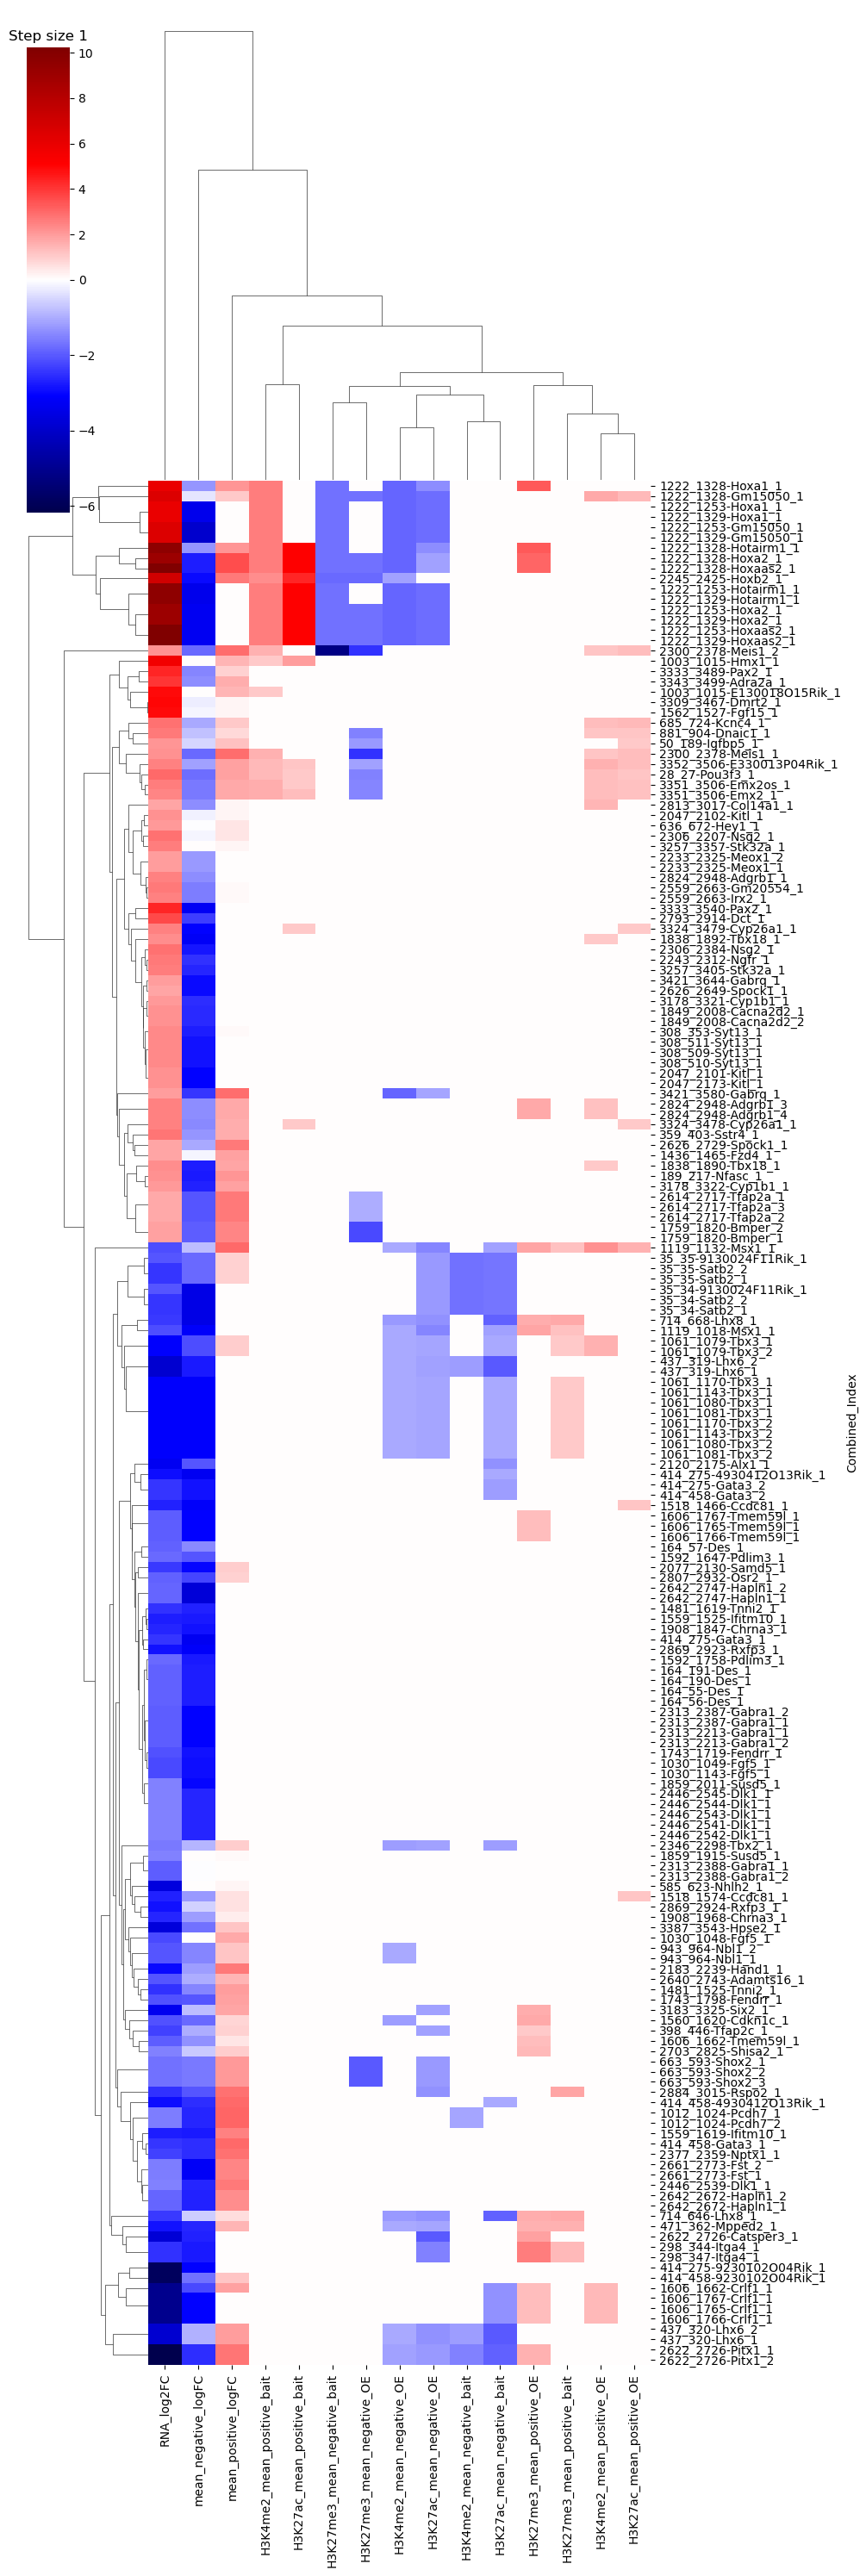

In [678]:
analyseMergedGraphResult_step_0['Combined_Index'] = analyseMergedGraphResult_step_0.cluster_id.astype(str) + '-' + analyseMergedGraphResult_step_0['name']

maximum = np.max(analyseMergedGraphResult_step_0[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)
minimum = np.min(analyseMergedGraphResult_step_0[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)

norm = mcolors.TwoSlopeNorm(vmin=minimum, vcenter=0, vmax=maximum)
# Set this new combined index as the index of the DataFrame
analyseMergedGraphResult_step_0.set_index('Combined_Index', inplace=True)
sns.clustermap(analyseMergedGraphResult_step_0[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]], cmap=cmap, norm=norm, figsize=(10, 30), yticklabels=True)
plt.title('Step size 1')

Text(0.5, 1.0, 'Step size 1')

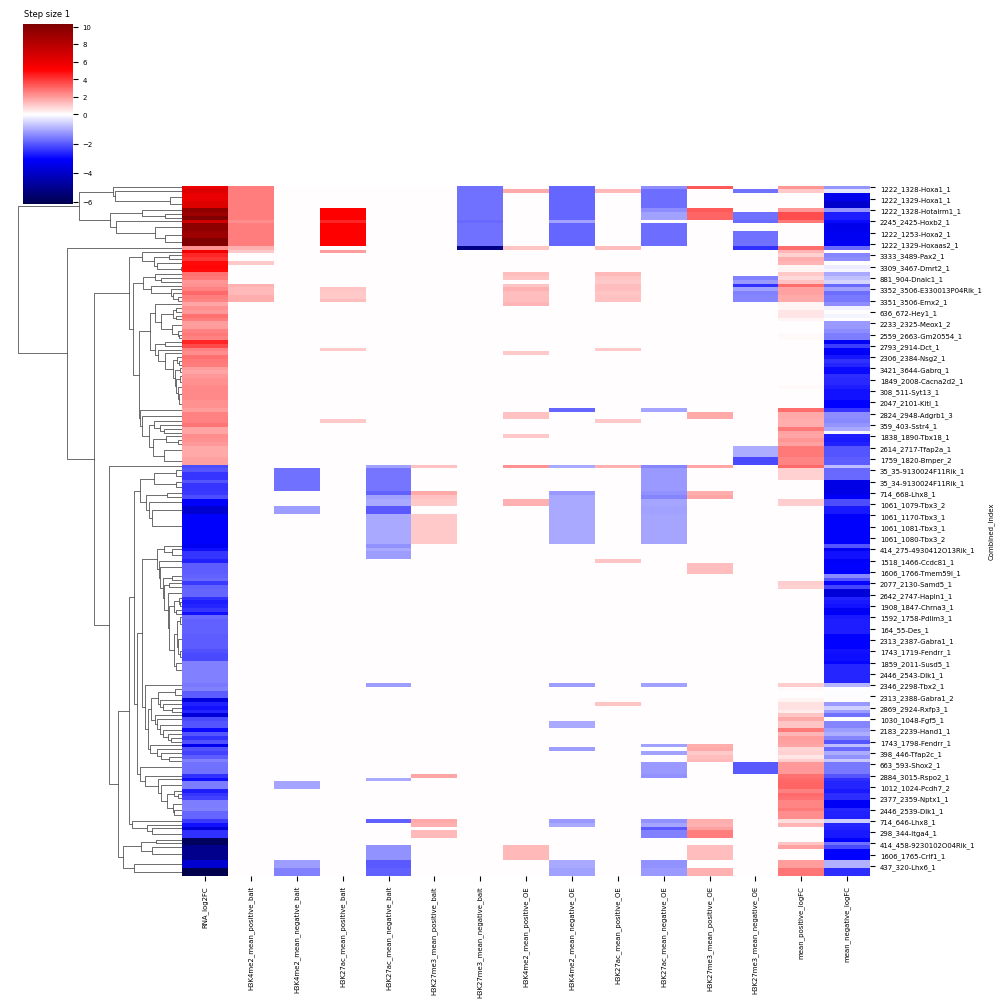

In [722]:
sns.clustermap(analyseMergedGraphResult_step_0[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]],  cmap=cmap, norm=norm, col_cluster=False)#, figsize=(10, 30), yticklabels=True)
plt.title('Step size 1')

In [645]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

Text(0.5, 1.0, 'Step size 2')

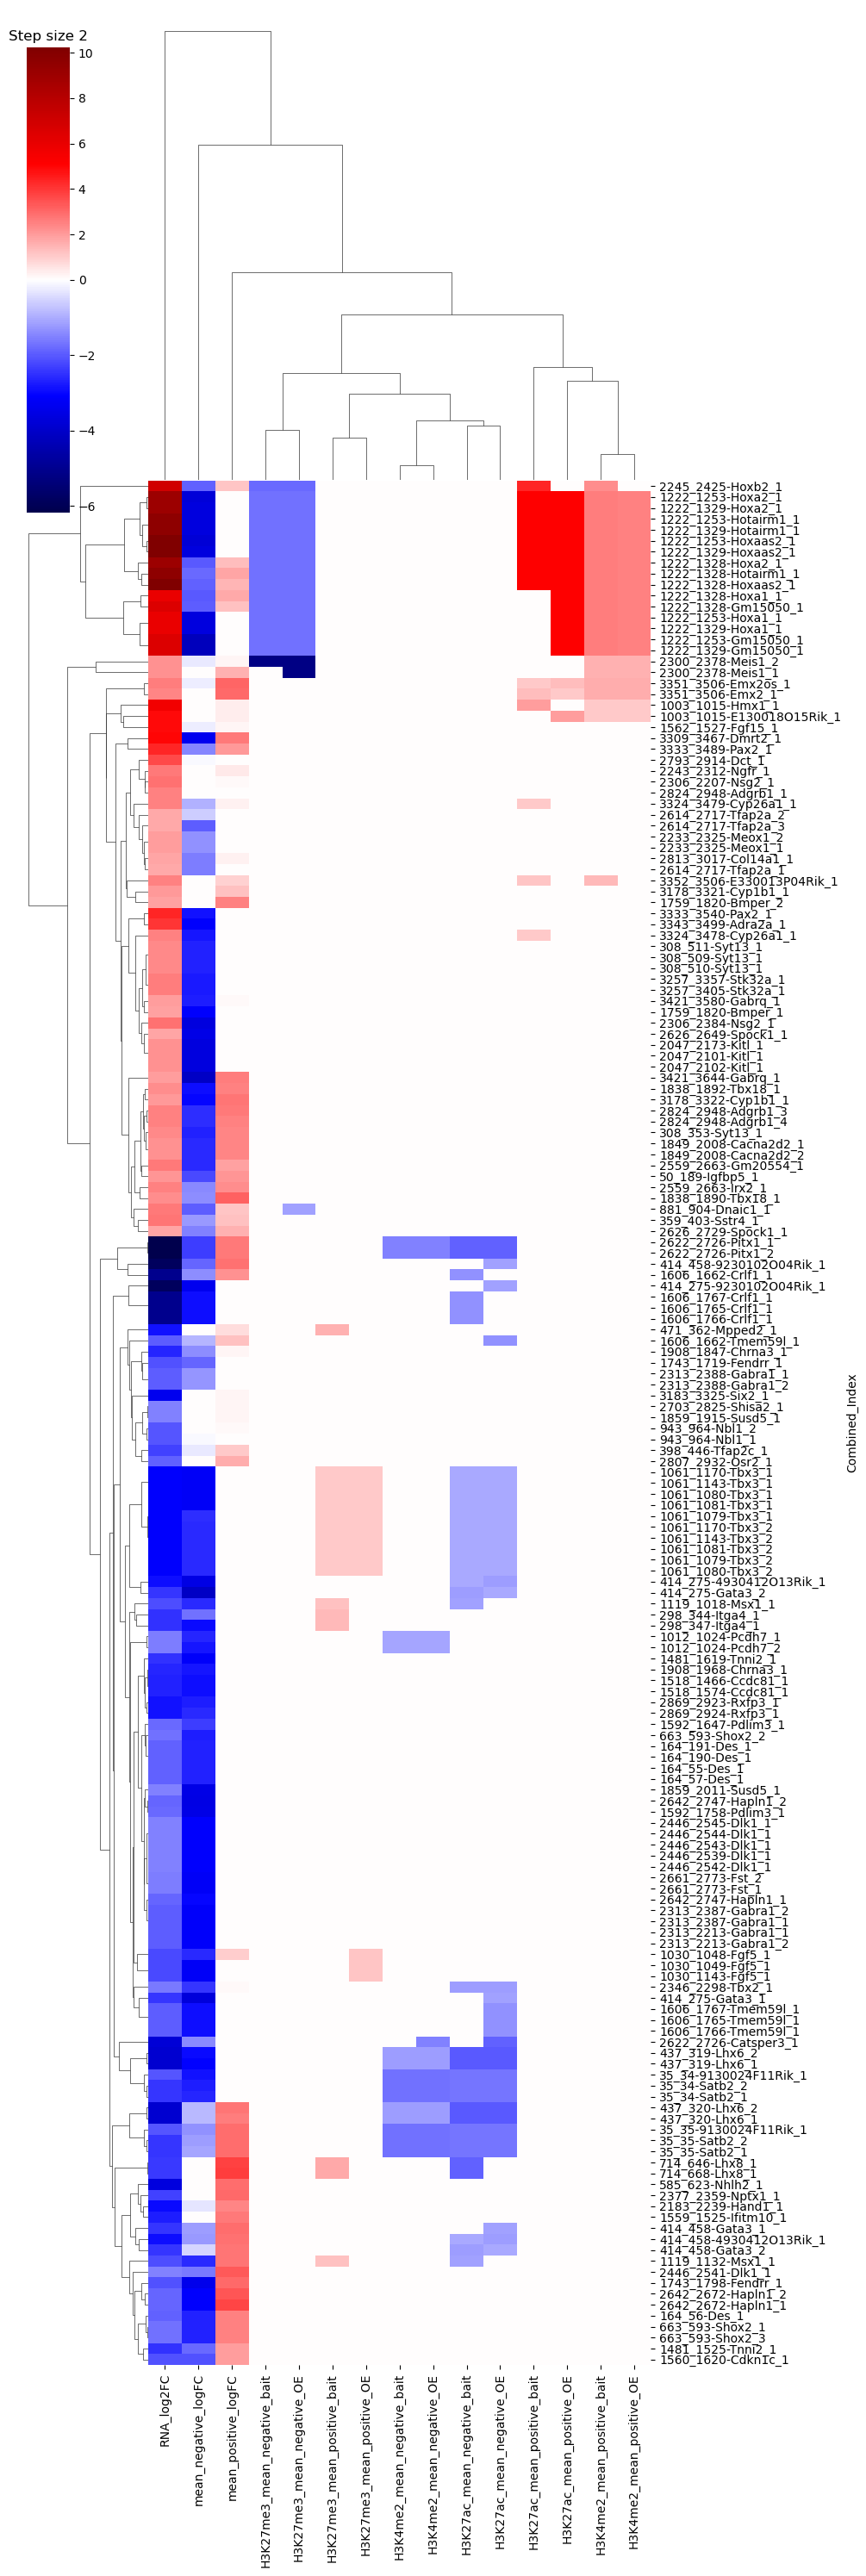

In [680]:
analyseMergedGraphResult_step_1.fillna(0, inplace=True)
# Create a new index that includes both the original index and the annotation
analyseMergedGraphResult_step_1['Combined_Index'] = analyseMergedGraphResult_step_1.cluster_id.astype(str) + '-' + analyseMergedGraphResult_step_1['name']

# Set this new combined index as the index of the DataFrame
analyseMergedGraphResult_step_1.set_index('Combined_Index', inplace=True)
# analyseMergedGraphResult_step_1.drop_duplicates(subset='name', keep='first')
cmap = plt.cm.seismic

# Define a normalization that sets 0 to white

maximum = np.max(analyseMergedGraphResult_step_1[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)
minimum = np.min(analyseMergedGraphResult_step_1[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)

norm = mcolors.TwoSlopeNorm(vmin=minimum, vcenter=0, vmax=maximum)
sns.clustermap(analyseMergedGraphResult_step_1[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]],  cmap=cmap, norm=norm, figsize=(10, 30), yticklabels=True)
plt.title('Step size 2')

Text(0.5, 1.0, 'Step size 2')

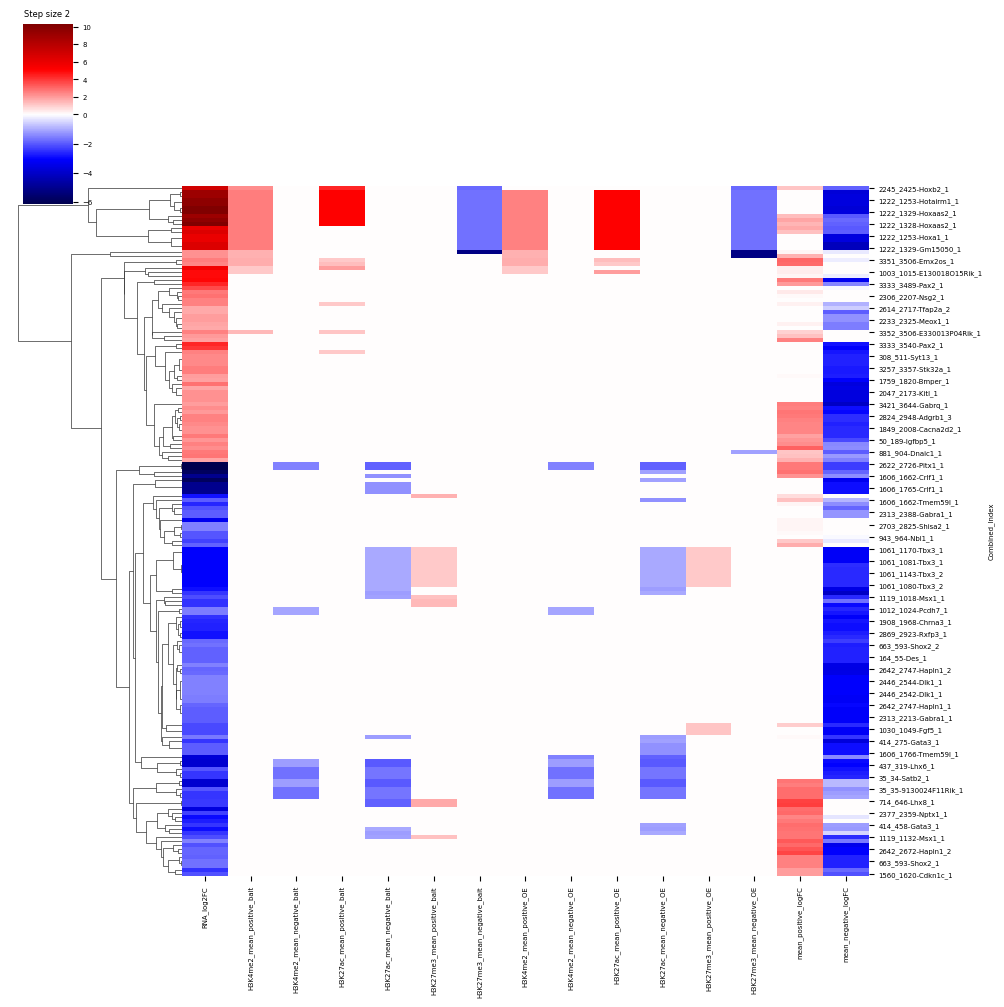

In [723]:

sns.clustermap(analyseMergedGraphResult_step_1[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]], cmap=cmap, norm=norm, col_cluster=False)#, figsize=(10, 30), yticklabels=True)
plt.title('Step size 2')

Text(0.5, 1.0, 'Step size 3')

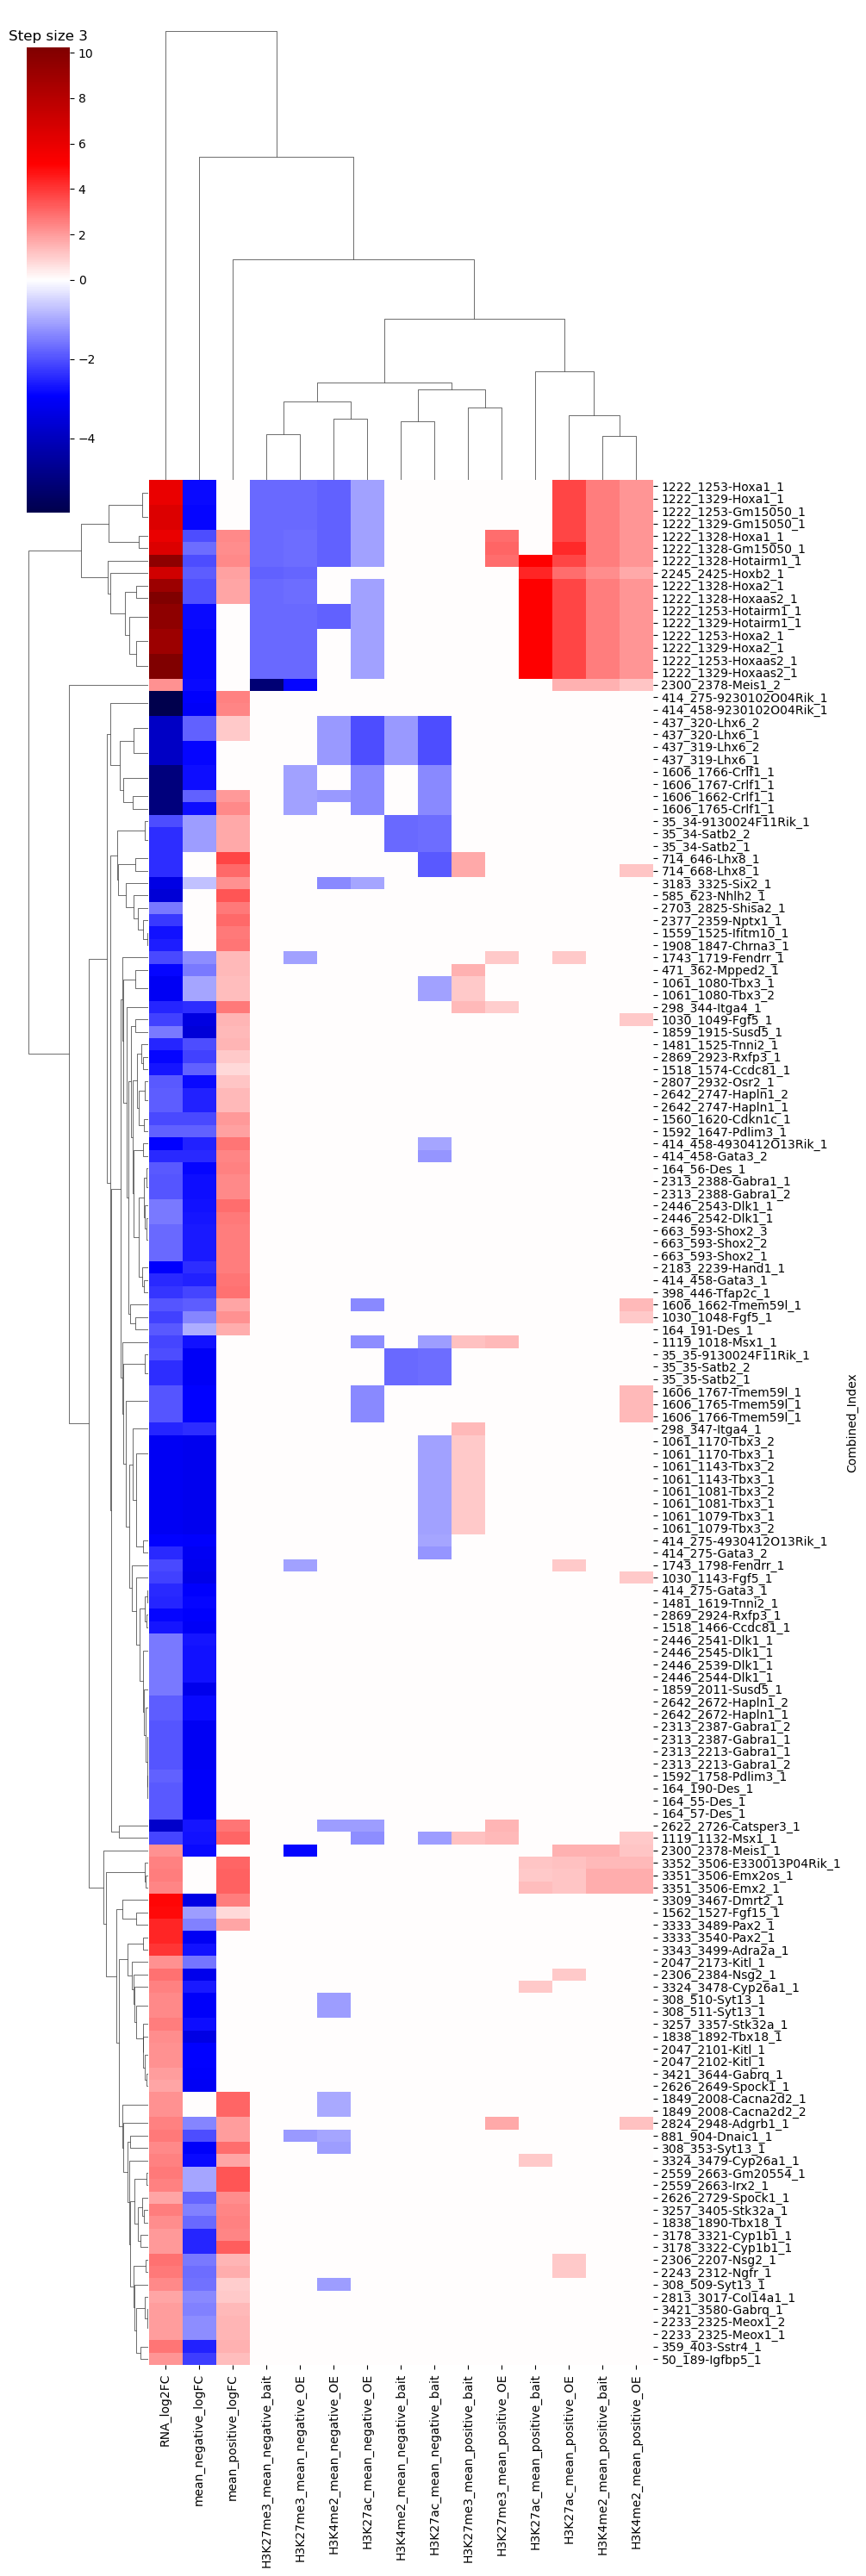

In [682]:
analyseMergedGraphResult_step_2.fillna(0, inplace=True)
analyseMergedGraphResult_step_2['Combined_Index'] = analyseMergedGraphResult_step_2.cluster_id.astype(str) + '-' + analyseMergedGraphResult_step_2['name']


cmap = plt.cm.seismic

# Define a normalization that sets 0 to white

maximum = np.max(analyseMergedGraphResult_step_2[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)
minimum = np.min(analyseMergedGraphResult_step_2[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)

norm = mcolors.TwoSlopeNorm(vmin=minimum, vcenter=0, vmax=maximum)
# Set this new combined index as the index of the DataFrame
analyseMergedGraphResult_step_2.set_index('Combined_Index', inplace=True)
clustermap = sns.clustermap(analyseMergedGraphResult_step_2[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]],  cmap=cmap, norm=norm, figsize=(10, 30), yticklabels=True)
plt.title('Step size 3')
# Add gridlines
# clustermap.ax_heatmap.grid(True, which='both', color='black', linestyle='-', linewidth=0.5)

# # Adjust the gridlines
# clustermap.ax_heatmap.set_xticks(np.arange(analyseMergedGraphResult_step_2.shape[1]+1)-0.5, minor=True)
# clustermap.ax_heatmap.set_yticks(np.arange(analyseMergedGraphResult_step_2.shape[0]+1)-0.5, minor=True)
# clustermap.ax_heatmap.grid(which="minor", color="black", linestyle='-', linewidth=0.5)
# clustermap.ax_heatmap.tick_params(which="minor", size=0)

Text(0.5, 1.0, 'Step size 3')

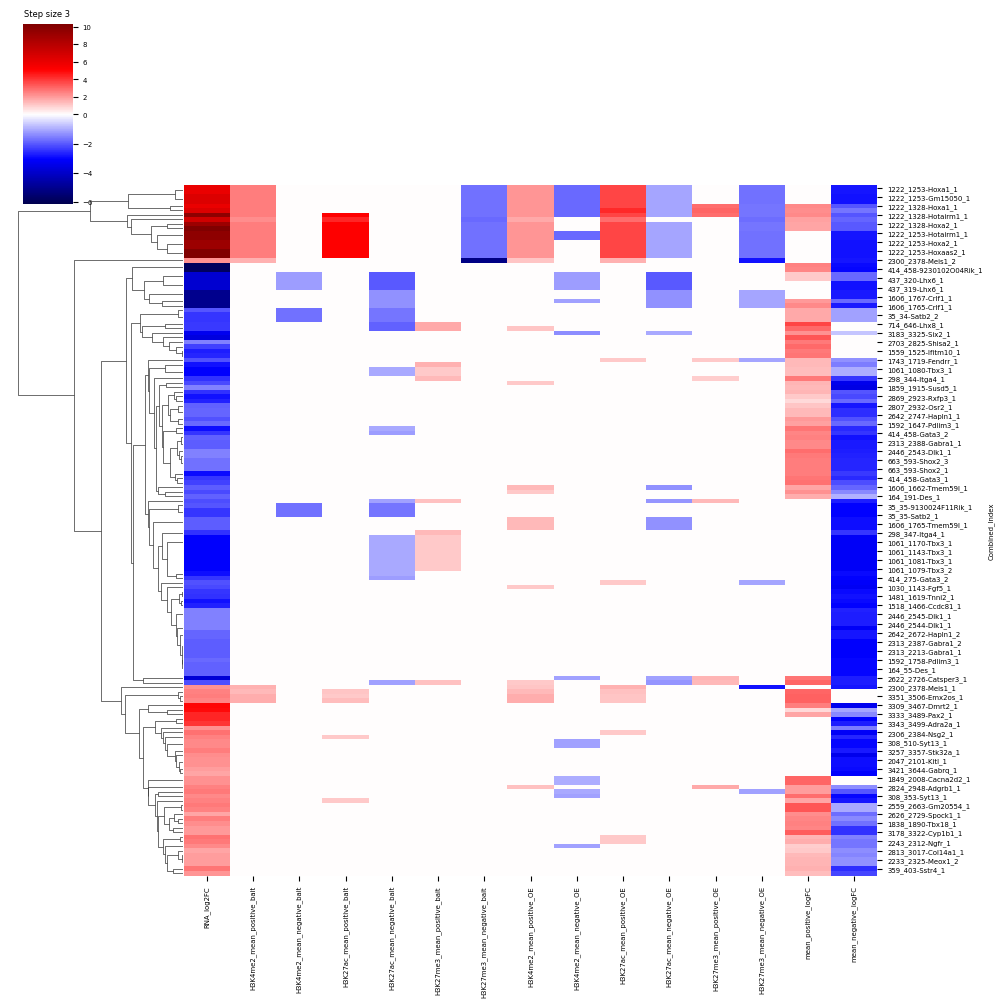

In [724]:
clustermap = sns.clustermap(analyseMergedGraphResult_step_2[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]],  cmap=cmap, norm=norm, col_cluster=False )#, figsize=(10, 30), yticklabels=True)
plt.title('Step size 3')
# Add gridlines

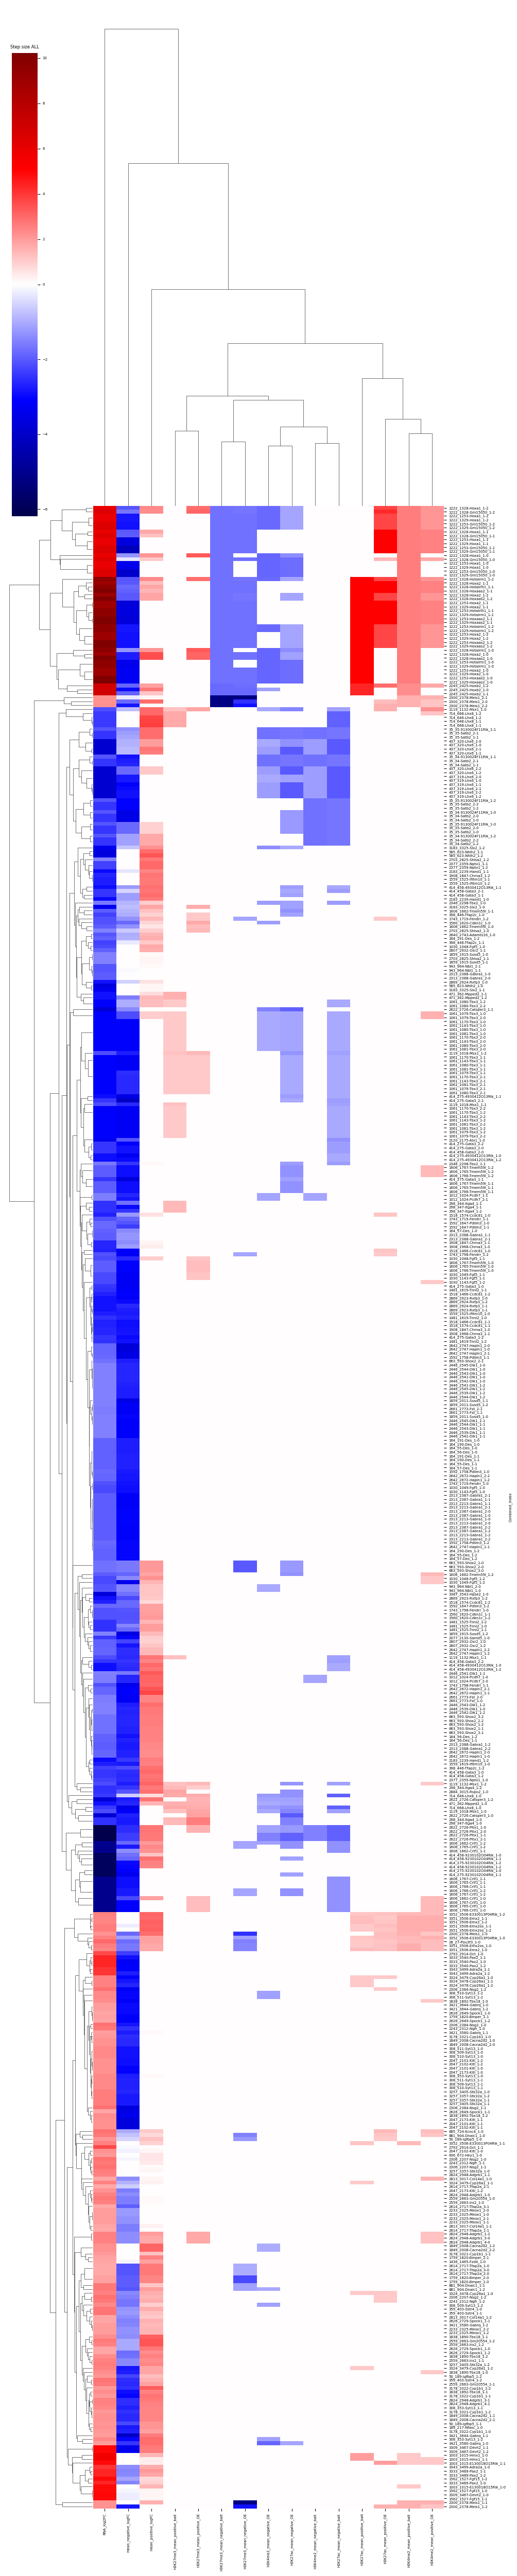

In [696]:
analyseMergedGraphResult.fillna(0, inplace=True)
analyseMergedGraphResult['Combined_Index'] = analyseMergedGraphResult.cluster_id.astype(str) + '-' + analyseMergedGraphResult['name']  + '-' + analyseMergedGraphResult['step'].astype(str)


cmap = plt.cm.seismic

# Define a normalization that sets 0 to white

maximum = np.max(analyseMergedGraphResult[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)
minimum = np.min(analyseMergedGraphResult[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)

norm = mcolors.TwoSlopeNorm(vmin=minimum, vcenter=0, vmax=maximum)
# Set this new combined index as the index of the DataFrame
analyseMergedGraphResult.set_index('Combined_Index', inplace=True)
plt.rcParams.update({'font.size': 5})

clustermap = sns.clustermap(analyseMergedGraphResult[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]],  cmap=cmap, norm=norm, figsize=(10, 50), yticklabels=True, annot_kws={"size": 5})
plt.title('Step size ALL')
# plt.xlabel('Features', fontsize=5)
# plt.ylabel('Samples', fontsize=5)

# # Customize tick labels' font size
# plt.xticks(fontsize=5)
# plt.yticks(fontsize=5)
plt.savefig(os.path.join(ROOT_PATH, "step_all.pdf"))

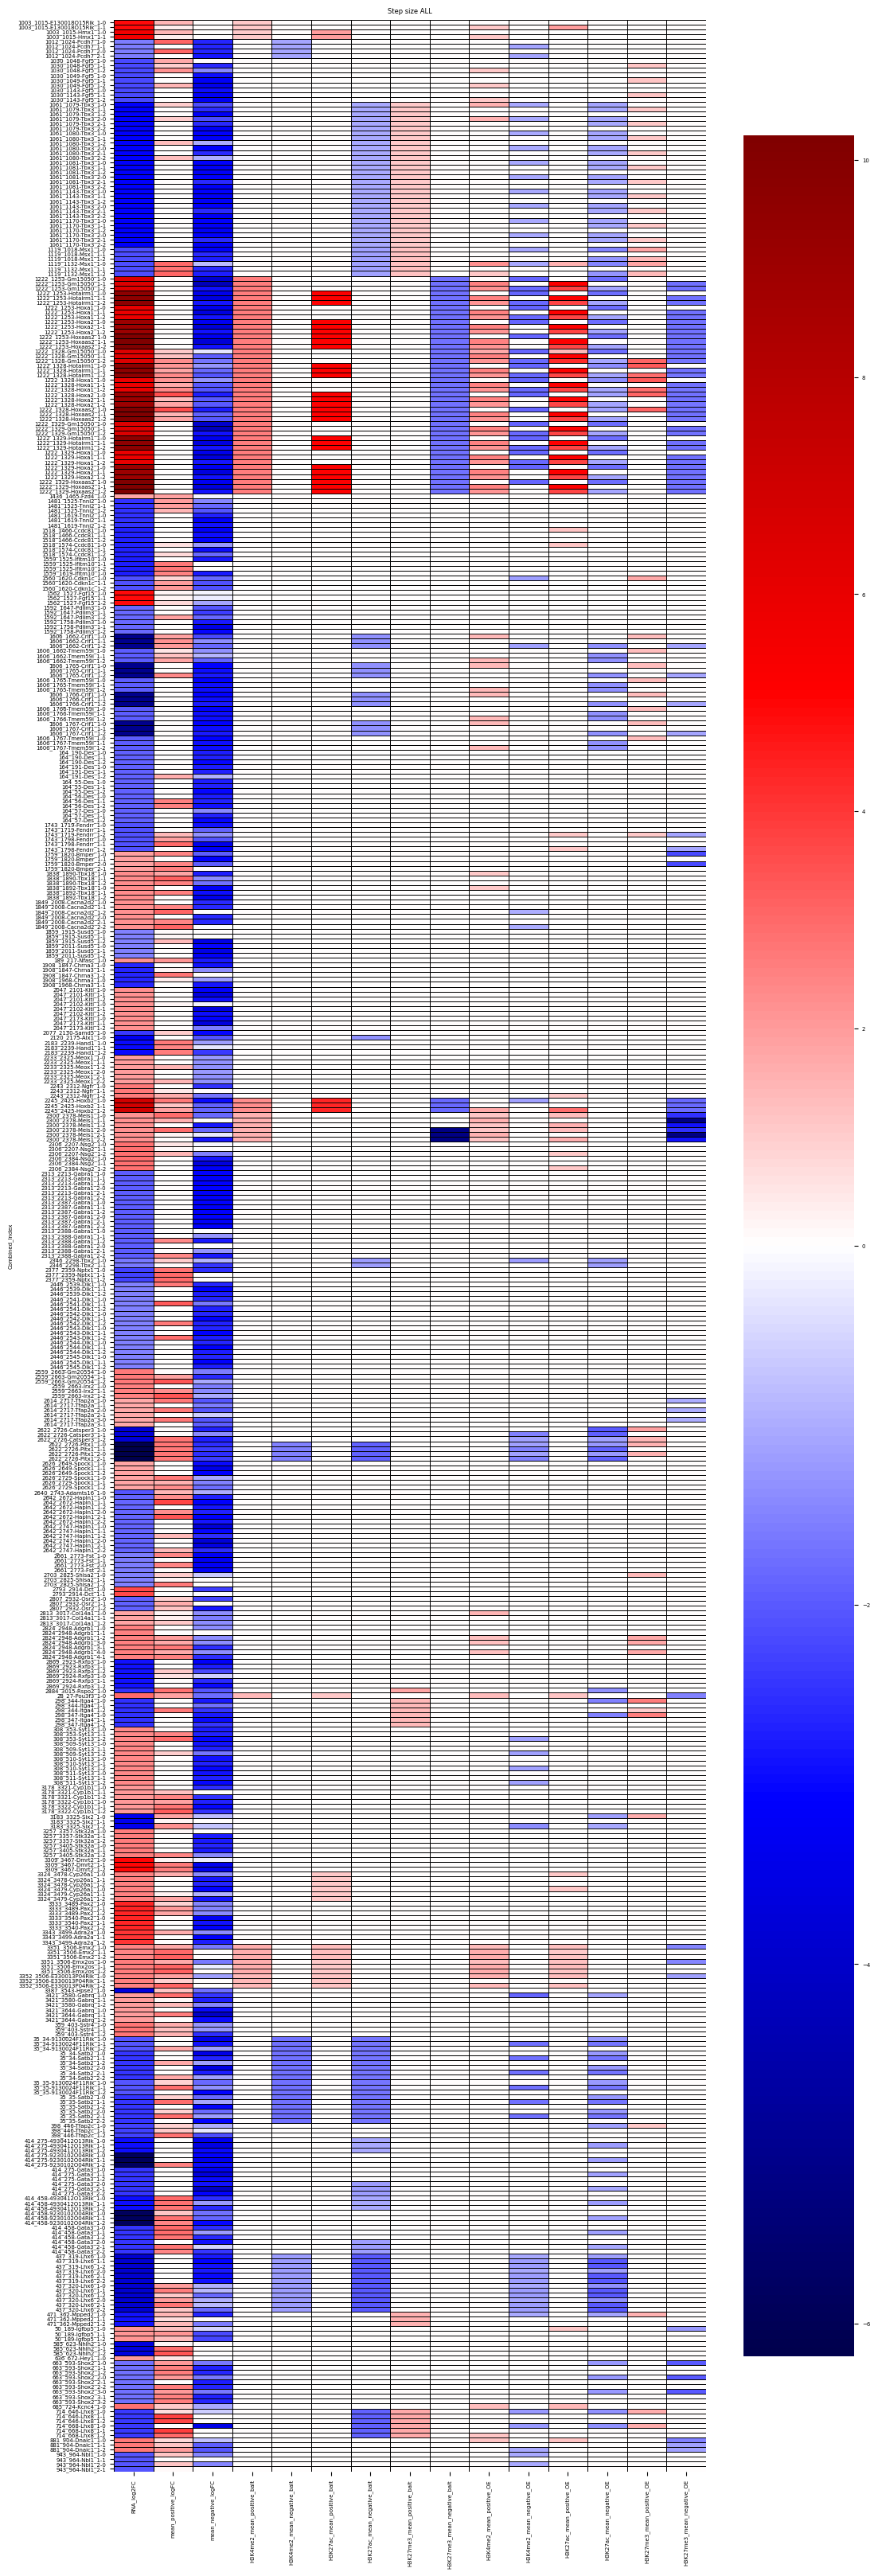

In [717]:
analyseMergedGraphResult.fillna(0, inplace=True)
analyseMergedGraphResult['Combined_Index'] = analyseMergedGraphResult.cluster_id.astype(str) + '-' + analyseMergedGraphResult['name']  + '-' + analyseMergedGraphResult['step'].astype(str)


cmap = plt.cm.seismic

# Define a normalization that sets 0 to white

maximum = np.max(analyseMergedGraphResult[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)
minimum = np.min(analyseMergedGraphResult[["RNA_log2FC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE",
                                                "mean_positive_logFC", "mean_negative_logFC"]].values)

# df_sorted = analyseMergedGraphResult.sort_values(by='Combined_Index', ascending=False)
df_sorted = analyseMergedGraphResult.sort_index()
norm = mcolors.TwoSlopeNorm(vmin=minimum, vcenter=0, vmax=maximum)
# Set this new combined index as the index of the DataFrame
analyseMergedGraphResult.set_index('Combined_Index', inplace=True)
plt.rcParams.update({'font.size': 5})
plt.figure(figsize=(12, 40)) 
clustermap = sns.heatmap(df_sorted[["RNA_log2FC", "mean_positive_logFC", "mean_negative_logFC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE"
                                                ]],  cmap=cmap, norm=norm, linewidth=0.5, linecolor='black', yticklabels=True, annot_kws={"size": 5})
plt.title('Step size ALL')
# plt.grid( color='black', linestyle='-', linewidth=0.5)

# plt.xlabel('Features', fontsize=5)
# plt.ylabel('Samples', fontsize=5)

# # Customize tick labels' font size
# plt.xticks(fontsize=5)
# plt.yticks(fontsize=5)
plt.savefig(os.path.join(ROOT_PATH, "step_all.pdf"))

In [726]:
analyseMergedGraphResult_step_0_subset = analyseMergedGraphResult_step_0[["RNA_log2FC", "mean_positive_logFC", "mean_negative_logFC", "H3K4me2_mean_positive_bait", "H3K4me2_mean_negative_bait", 'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait', "H3K27me3_mean_positive_bait", "H3K27me3_mean_negative_bait", 
                                                "H3K4me2_mean_positive_OE", "H3K4me2_mean_negative_OE", 'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE', "H3K27me3_mean_positive_OE", "H3K27me3_mean_negative_OE"
                                                ]]

In [729]:
analyseMergedGraphResult_step_0_subset_RNA_up = analyseMergedGraphResult_step_0_subset[analyseMergedGraphResult_step_0_subset["RNA_log2FC"] >= 0]
analyseMergedGraphResult_step_0_subset_RNA_down = analyseMergedGraphResult_step_0_subset[analyseMergedGraphResult_step_0_subset["RNA_log2FC"] < 0]

In [734]:
analyseMergedGraphResult_step_0_subset_RNA_down_rewire = analyseMergedGraphResult_step_0_subset_RNA_down[(analyseMergedGraphResult_step_0_subset_RNA_down["mean_positive_logFC"] != 0) & (analyseMergedGraphResult_step_0_subset_RNA_down["mean_negative_logFC"] != 0)]
analyseMergedGraphResult_step_0_subset_RNA_up_rewire = analyseMergedGraphResult_step_0_subset_RNA_up[(analyseMergedGraphResult_step_0_subset_RNA_up["mean_positive_logFC"] != 0) & (analyseMergedGraphResult_step_0_subset_RNA_up["mean_negative_logFC"] != 0)]

analyseMergedGraphResult_step_0_subset_RNA_down_loss_of_structure = analyseMergedGraphResult_step_0_subset_RNA_down[(analyseMergedGraphResult_step_0_subset_RNA_down["mean_positive_logFC"] == 0) & (analyseMergedGraphResult_step_0_subset_RNA_down["mean_negative_logFC"] != 0)]
analyseMergedGraphResult_step_0_subset_RNA_down_gain_of_structure = analyseMergedGraphResult_step_0_subset_RNA_down[(analyseMergedGraphResult_step_0_subset_RNA_down["mean_positive_logFC"] != 0) & (analyseMergedGraphResult_step_0_subset_RNA_down["mean_negative_logFC"] == 0)]

analyseMergedGraphResult_step_0_subset_RNA_up_loss_of_structure = analyseMergedGraphResult_step_0_subset_RNA_up[(analyseMergedGraphResult_step_0_subset_RNA_up["mean_positive_logFC"] == 0) & (analyseMergedGraphResult_step_0_subset_RNA_up["mean_negative_logFC"] != 0)]
analyseMergedGraphResult_step_0_subset_RNA_up_gain_of_structure = analyseMergedGraphResult_step_0_subset_RNA_up[(analyseMergedGraphResult_step_0_subset_RNA_up["mean_positive_logFC"] != 0) & (analyseMergedGraphResult_step_0_subset_RNA_up["mean_negative_logFC"] == 0)]


In [746]:
analyseMergedGraphResult_step_0_subset_RNA_up_gain_of_structure.columns

Index(['RNA_log2FC', 'mean_positive_logFC', 'mean_negative_logFC',
       'H3K4me2_mean_positive_bait', 'H3K4me2_mean_negative_bait',
       'H3K27ac_mean_positive_bait', 'H3K27ac_mean_negative_bait',
       'H3K27me3_mean_positive_bait', 'H3K27me3_mean_negative_bait',
       'H3K4me2_mean_positive_OE', 'H3K4me2_mean_negative_OE',
       'H3K27ac_mean_positive_OE', 'H3K27ac_mean_negative_OE',
       'H3K27me3_mean_positive_OE', 'H3K27me3_mean_negative_OE'],
      dtype='object')

In [751]:
def rewireInformation(pDataFrame, pRNAColumnName, pIteractionColumnNameUp, pIteractionColumnNameDown):
    RNA_up_down = [pDataFrame[pDataFrame[pRNAColumnName] >= 0], pDataFrame[pDataFrame[pRNAColumnName] < 0]]
    RNA_rewire_list = []
    for element in RNA_up_down:
        RNA_rewire_list.append(element[(element[pIteractionColumnNameUp] != 0 )&(element[pIteractionColumnNameDown] != 0)])
        RNA_rewire_list.append(element[(element[pIteractionColumnNameUp] == 0 )&(element[pIteractionColumnNameDown] != 0)])
        RNA_rewire_list.append(element[(element[pIteractionColumnNameUp] != 0 )&(element[pIteractionColumnNameDown] == 0)])

    result_names = ['RNA up rewire', 'RNA up exclusive loss', 'RNA up exclusive gain', 'RNA down rewire', 'RNA down exclusive loss', 'RNA down exclusive gain']
    result_dict = {}
    for i, name in enumerate(result_names):
        result_dict[name] = len(RNA_rewire_list[i]) / len(pDataFrame)

    bait_columns = [col for col in pDataFrame if col.endswith("bait")]
    OE_columns = [col for col in pDataFrame if col.endswith("OE")]


    for i, element in enumerate(RNA_rewire_list):
        amount_of_bait_histones = []
        for bait in bait_columns:
            amount_of_bait_histones.append(len(element[element[bait] != 0]))
        
        amount_of_OE_histones = []
        for OE in OE_columns:
            amount_of_OE_histones.append(len(element[element[OE] != 0]))

        result_dict[result_names[i] + ' bait histone change'] = np.mean(amount_of_bait_histones) / len(pDataFrame)
        result_dict[result_names[i] + ' OE histone change'] = np.mean(amount_of_OE_histones) / len(pDataFrame)


    return result_dict


In [752]:
rewireInformation(analyseMergedGraphResult_step_0_subset, "RNA_log2FC", "mean_positive_logFC", "mean_negative_logFC")

{'RNA up rewire': 0.22404371584699453,
 'RNA up exclusive loss': 0.16393442622950818,
 'RNA up exclusive gain': 0.01639344262295082,
 'RNA down rewire': 0.26229508196721313,
 'RNA down exclusive loss': 0.31693989071038253,
 'RNA down exclusive gain': 0.01639344262295082,
 'RNA up rewire bait histone change': 0.025500910746812388,
 'RNA up rewire OE histone change': 0.0546448087431694,
 'RNA up exclusive loss bait histone change': 0.02459016393442623,
 'RNA up exclusive loss OE histone change': 0.02367941712204007,
 'RNA up exclusive gain bait histone change': 0.00273224043715847,
 'RNA up exclusive gain OE histone change': 0.0,
 'RNA down rewire bait histone change': 0.02641165755919854,
 'RNA down rewire OE histone change': 0.04735883424408014,
 'RNA down exclusive loss bait histone change': 0.03551912568306011,
 'RNA down exclusive loss OE histone change': 0.040983606557377046,
 'RNA down exclusive gain bait histone change': 0.0,
 'RNA down exclusive gain OE histone change': 0.0}

In [749]:

preprocess = [col for col in analyseMergedGraphResult_step_0_subset if col.endswith("bait")]

In [750]:
preprocess

['H3K4me2_mean_positive_bait',
 'H3K4me2_mean_negative_bait',
 'H3K27ac_mean_positive_bait',
 'H3K27ac_mean_negative_bait',
 'H3K27me3_mean_positive_bait',
 'H3K27me3_mean_negative_bait']

In [159]:
# write out clusters, with their ids, the bait name and the OE. all with their chromosomal location
#
# Are the genes of a cluster similar regulated?
# - RNA of genes similar high? compare tpm
# - 

{'name': 'HOXA2-001',
 'colorType': 'green',
 'position': 'chr7:27137355-27143253',
 'partition': 300,
 'partition_color': 300}

In [397]:
# gm12878_rna_counts

In [403]:
gm12878_rna_counts[gm12878_rna_counts[0] == 'HOXC4']

,0,1,2,3
8536,HOXC4,403,240,321.5


In [396]:
dictionary['A1CF'][3]

12.0

In [166]:
import pyBigWig

In [199]:
import numpy as np

path_rna_gm12878_R1 = "/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/GM12878_RNA/GSM758559_wgEncodeCshlLongRnaSeqGm12878CellPapMinusRawSigRep1.bigWig"
path_rna_gm12878_R2 = "/Users/wolffjoa/Library/CloudStorage/OneDrive-mh-hannover.de/data/epigenetic-graph-analyzer/GM12878_RNA/GSM758559_wgEncodeCshlLongRnaSeqGm12878CellPapMinusRawSigRep2.bigWig"

# Open the bigWig file
bw = pyBigWig.open()

# Specify the genomic location
chromosome = 'chr1'
start = 100231939
end = 100238229

# Retrieve the data from the specific location
# Assuming you have a NumPy array called 'data'
data = bw.values(chromosome, start, end, numpy=True)

# Create a boolean mask to identify NaN values
mask = np.isnan(data)

# Filter out the NaN values
filtered_data = data[~mask]

# Print the filtered data
print(filtered_data.mean())
print(filtered_data.max())



RuntimeError: Received an error during file opening!

In [191]:
promoters

,Chromosome,Start,End,Name
0,chr1,100105297,100123456,PALMD-001
1,chr1,10021141,9990584,"LZIC-001,LZIC-005,LZIC-202,LZIC-201"
2,chr1,100231939,100238229,"FRRS1-001,FRRS1-201"
3,chr1,100249718,100249837,U4.31-201
4,chr1,100294309,100296677,AL451051.1-201
...,...,...,...,...
21856,chrY,2800574,2805795,"ZFY-001,ZFY-002,ZFY-202,ZFY-201,ZFY-203"
21857,chrY,6740033,6740152,"AMELY-001,AMELY-002,AMELY-201"
21858,chrY,6781549,6781668,"TBL1Y-001,TBL1Y-002,TBL1Y-003,TBL1Y-201"
21859,chrY,7241381,7241500,U6.1084-201


In [195]:
# promoters["Name"].contains('FRRS1-001')

promoters.df[promoters.df["Name"].str.contains("FRRS1-001")]

,Chromosome,Start,End,Name
2,chr1,100231939,100238229,"FRRS1-001,FRRS1-201"


In [379]:
def computeRNAsimilarity(partition_sample, bait_list, graph, RNA_counts):
    
    mean_values = []
    max_values = []
    min_values = []
    var_values = []
    partition_ids = []
    for i, partition in enumerate(partition_sample):
        partition_list = []
        for node in partition:
            if node < len(bait_list):
                # print(graph.nodes[node]['position'], graph.nodes[node]['name'])
                data = RNA_counts[RNA_counts[0] == graph.nodes[node]['name'].split('-')[0]]
                if (len(data) == 0):
                    continue
                partition_list.append(data.values[0][3])

        if len(partition_list) >= 2:
            mean_values.append(np.mean(partition_list))
            max_values.append(np.max(partition_list))
            min_values.append(np.min(partition_list))
            var_values.append(np.var(partition_list))

            partition_ids.append(i)
    mean_values = np.array(mean_values)
    max_values = np.array(max_values)
    min_values = np.array(min_values)
    var_values = np.array(var_values)
    partition_ids = np.array(partition_ids)

    return mean_values, max_values, min_values, var_values, partition_ids

In [380]:
mean_values, max_values, min_values, var_values, partition_ids = computeRNAsimilarity(partition_GM12878, bait_list_GM12878, G_Pinna_GM12878, gm12878_rna_counts)



In [344]:
partition_ids = np.arange(len(partition_GM12878))
mask = mean_values == np.float32(0)
partition_ids = partition_ids[~mask]
mean_values = mean_values[~mask]
max_values = max_values[~mask]
min_values = min_values[~mask]
mean_max = mean_max[~mask]
mean_min = mean_min[~mask]



IndexError: boolean index did not match indexed array along dimension 0; dimension is 3369 but corresponding boolean dimension is 556

In [352]:
mask = mean_values == np.float32(0)

In [355]:
len(mean_values
    )

556

In [317]:
# gm12878_rna_counts[3] = np.mean(gm12878_rna_counts[1] + gm12878_rna_counts[2])
gm12878_rna_counts[1] = gm12878_rna_counts[1].astype(int)
gm12878_rna_counts[2] = gm12878_rna_counts[2].astype(int)
gm12878_rna_counts[3] = gm12878_rna_counts[1] + gm12878_rna_counts[2]
gm12878_rna_counts[3] = gm12878_rna_counts[3] / 2

In [310]:
gm12878_rna_counts.dtypes

0     object
1      int64
2      int64
3    float64
dtype: object

In [318]:
gm12878_rna_counts

,0,1,2,3
0,A1BG,68,16,42.0
1,A1BG-AS1,48,20,34.0
2,A1CF,10,14,12.0
3,A2M,17,9,13.0
4,A2M-AS1,10,10,10.0
...,...,...,...,...
28260,ZYG11A,1456,1168,1312.0
28261,ZYG11B,2589,2620,2604.5
28262,ZYX,297,86,191.5
28263,ZZEF1,5384,2464,3924.0


In [376]:
gm12878_rna_counts[gm12878_rna_counts[0] == "PALMD" ].values[0][3]

7.0

In [224]:
import numpy as np

n = len(partition_GM12878)  # replace with your desired value of n
arr = np.arange(len(partition_GM12878))

print(arr)


[   0    1    2 ... 3366 3367 3368]


In [226]:
import numpy as np

# Example arrays
array1 = np.array([3, 1, 4, 2])
array2 = np.array(['C', 'A', 'D', 'B'])

# Sort array1 and get the indices
sorted_indices = np.argsort(array1)

# Sort array1 and array2 based on the sorted indices
sorted_array1 = array1[sorted_indices]
sorted_array2 = array2[sorted_indices]

# Print the sorted arrays
print(sorted_array1)  # [1 2 3 4]
print(sorted_array2)  # ['A' 'B' 'C' 'D']


3369

In [365]:
mean_values[sorted_indices]

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 2.50000000e-01,
       2.50000000e-01, 2.50000000e-01, 2.50000000e-01, 5.00000000e-01,
       7.50000000e-01, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.25000000e+00, 1.25000000e+00, 1.33333333e+00, 1.75000000e+00,
       2.16666667e+00, 2.50000000e+00, 2.66666667e+00, 2.75000000e+00,
       2.75000000e+00, 2.75000000e+00, 2.75000000e+00, 2.75000000e+00,
       2.75000000e+00, 3.00000000e+00, 3.00000000e+00, 3.16666667e+00,
       3.25000000e+00, 3.25000000e+00, 3.33333333e+00, 3.50000000e+00,
       3.75000000e+00, 3.75000000e+00, 4.40000000e+00, 4.50000000e+00,
       4.50000000e+00, 4.50000000e+00, 4.75000000e+00, 5.00000000e+00,
       5.19444444e+00, 5.50000000e+00, 5.50000000e+00, 5.50000000e+00,
       5.50000000e+00, 5.75000000e+00, 6.25000000e+00, 6.25000000e+00,
      

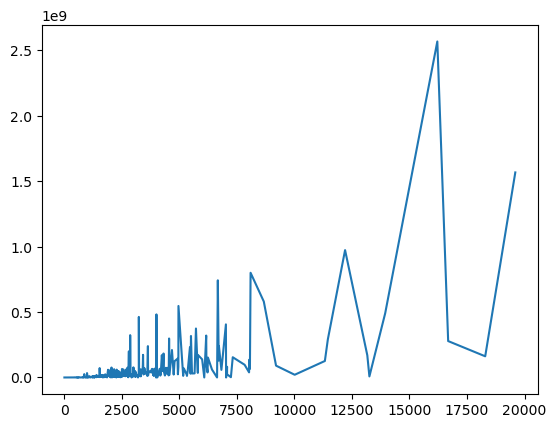

In [364]:
sorted_indices = np.argsort(mean_values)

# Sort array1 and array2 based on the sorted indices
sorted_array1 = mean_values[sorted_indices]
sorted_array2 = var_values[sorted_indices]
plt.plot(sorted_array1, sorted_array2)

In [160]:
partition_GM12878

[{0, 2237, 2239, 2245, 2246, 48130, 48469, 48883, 48914, 48959},
 {2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  20,
  21,
  23,
  24,
  25,
  26,
  49012,
  49037,
  49039,
  49040,
  49042,
  49043,
  49049,
  49054,
  49059,
  49062,
  49103,
  49117,
  49118,
  49121,
  49122,
  49127,
  49129,
  49135,
  49136,
  49153,
  49154,
  49157,
  49164,
  49165,
  49166,
  49191,
  49193,
  49210,
  49216,
  49225,
  49235,
  49236,
  49237,
  49241,
  49245,
  49247,
  49251,
  49265,
  49333,
  49362,
  49363,
  49365,
  49367,
  49375,
  49376,
  49456,
  49481,
  49484,
  49485,
  49497,
  49499,
  49500,
  49507,
  49508,
  49510,
  49515,
  49534,
  49539,
  49546,
  49547},
 {1, 28, 36, 23825, 23861},
 {44, 46, 51332},
 {45,
  47,
  48,
  49,
  50,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  72,
  73,
  74,
  75,
  76,
  78,
  79,
  81,
  82,
  84,
  85,
  86,
  89,
  

In [161]:
G_Pinna_CD34.nodes[8958]


{'name': 'HOXA2-001',
 'colorType': 'green',
 'position': 'chr7:27137355-27143253',
 'partition': 580,
 'partition_color': 580}

In [125]:
G_Pinna_GM12878.nodes[8958]


{'name': 'HOXA2-001',
 'colorType': 'green',
 'partition': 1030,
 'partition_color': 1030}

## Is the bait still in the same community between conditions?

### Compute the jaccard similarity between all communities

In [127]:
def jaccardSimiliarityCommunities(community_1, community_2, number_of_baits):
    intersection_communities_nodes = []
    intersection_communities_jaccard = np.zeros((len(community_1), len(community_2)))
    intersection_communities_bait_jaccard = np.zeros((len(community_1), len(community_2)))
    for i in range(len(community_1)):
        intersection_communities_nodes.append({})
        for j in range(len(community_2)):
            intersection = community_1[i].intersection(community_2[j])

            if len(intersection) > 0:
                intersection_communities_nodes[i][j] = intersection
                intersection_communities_jaccard[i, j] = len(intersection) / len(community_1[i].union(community_2[j]))
                bait_intersection = {x for x in intersection if x <= number_of_baits}
                bait_community_1 = {x for x in community_1[i] if x <= number_of_baits}
                bait_community_2 = {x for x in community_2[j] if x <= number_of_baits}
                intersection_communities_bait_jaccard[i, j] = len(bait_intersection) / len(bait_community_1.union(bait_community_2))

    return intersection_communities_nodes, intersection_communities_jaccard, intersection_communities_bait_jaccard

In [128]:
intersection_communities_nodes, intersection_communities_jaccard, intersection_communities_bait_jaccard = jaccardSimiliarityCommunities(partition_CD34, partition_GM12878, sample_matrix_CD34.shape[0])

In [130]:
intersection_communities_nodes[1030]

{728: {6517,
  6518,
  6519,
  6520,
  6521,
  6522,
  6523,
  6524,
  6525,
  6526,
  6527,
  624482,
  624483,
  624486,
  624501,
  624528,
  624591,
  624594,
  624616,
  624619,
  624634,
  624635,
  624640,
  624650,
  624662,
  624671}}

In [131]:
# Assuming your 2D array is named 'arr'
# Retrieve the 10 highest numbers per row
top_10_values = np.sort(intersection_communities_bait_jaccard, axis=1)[:, ::-1][:, :5]

# Retrieve the indices of the columns for the top 10 values
top_10_indices = np.argsort(intersection_communities_bait_jaccard, axis=1)[:, ::-1][:, :5]

# Print the results
print("Top 10 values per row:")
print(top_10_values)
print("Indices of the columns for the top 10 values:")
print(top_10_indices)


Top 10 values per row:
[[0.2        0.         0.         0.         0.        ]
 [0.04545455 0.         0.         0.         0.        ]
 [0.86956522 0.         0.         0.         0.        ]
 ...
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]]
Indices of the columns for the top 10 values:
[[   0  766  782  781  780]
 [ 145  766  782  781  780]
 [ 145  766  782  781  780]
 ...
 [2336  766  782  781  780]
 [2336  766  782  781  780]
 [2336  766  782  781  780]]


In [132]:
# Assuming your 2D array is named 'arr'
# Retrieve the 10 highest numbers per row
top_10_values_communities = np.sort(intersection_communities_jaccard, axis=1)[:, ::-1][:, :5]

# Retrieve the indices of the columns for the top 10 values
top_10_indices_communities = np.argsort(intersection_communities_jaccard, axis=1)[:, ::-1][:, :5]

# Print the results
print("Top 10 values per row:")
print(top_10_values)
print("Indices of the columns for the top 10 values:")
print(top_10_indices)

Top 10 values per row:
[[0.2        0.         0.         0.         0.        ]
 [0.04545455 0.         0.         0.         0.        ]
 [0.86956522 0.         0.         0.         0.        ]
 ...
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]]
Indices of the columns for the top 10 values:
[[   0  766  782  781  780]
 [ 145  766  782  781  780]
 [ 145  766  782  781  780]
 ...
 [2336  766  782  781  780]
 [2336  766  782  781  780]
 [2336  766  782  781  780]]


In [93]:
top_10_indices[1268]

array([ 235, 1055,  347,  360,  359])

In [94]:
top_10_indices_communities[12]

array([  7, 354, 348, 349, 350])

In [55]:
top_10_values_communities[1268]

array([0.41145833, 0.02281369, 0.00581395, 0.        , 0.        ])

In [111]:
top_10_values[1268]

array([1., 0., 0., 0., 0.])

In [57]:
intersection_communities_nodes[1268]

[{8146, 8147, 642455, 642467, 642579, 642580},
 {641455},
 {8133,
  8137,
  8138,
  8139,
  8140,
  8142,
  8143,
  8144,
  8145,
  8761,
  8765,
  8766,
  8767,
  8768,
  8769,
  8771,
  8773,
  8774,
  8775,
  8776,
  641958,
  641960,
  641961,
  642001,
  642002,
  642003,
  642013,
  642074,
  642075,
  642076,
  642077,
  642078,
  642079,
  642080,
  642081,
  642082,
  642083,
  642084,
  642085,
  642086,
  642087,
  642088,
  642089,
  642096,
  642198,
  642199,
  642309,
  642310,
  642351,
  642352,
  642353,
  642355,
  642356,
  642358,
  642359,
  642360,
  642361,
  642411,
  642413,
  642426,
  642436,
  642437,
  642549,
  642551,
  642552,
  642554,
  642555,
  642559,
  642560,
  642562,
  642602,
  642606,
  642646,
  642649,
  642650,
  642651,
  642653,
  642671,
  642672}]

After the jaccard similarity sorting:
- Which clusters have the identical baits?
- Which baits are equal between clusters?
- Which baits changed the cluster?
- Which baits are exclusive in one sample? For example jaccard similarity of Hoxa2 cluster is 0.76 to the clostest one, 0.03 to the next, and to all other 0. Where are the missing 0.2? Ideas: Baits are exclusive in sample 1 xor sample 2.

- For equal: 
  - How did the histone / RNA changed between the conditions? 
    - per both sides of the interaction get the histone / RNA / ATAC data, with replicates for DESeq2 table
  - How did the interaction strength changed? (Binary contact number change / summed value change / mean change) per community
  - Did we get new OE interactions of those same baits?

- Baits changed cluster:
  - How did the histone / RNA changed between the conditions? 
  - How did it changed at those contacts that were lost / gained? Identifiy the contacts responsible for the loss / gain within the community. Get for both ends of a gained / lost contact from both samples the Histone / RNA / ATAC data for Deseq2 table

- Exclusive in one sample:
  - How did the histone / RNA changed between the conditions at the locations of baits / OE? 
  - Which OE have a degree of 1, 2, 3, ..., n?

Can we identifiy patterns? 
- 


#### Plot the distribution of the jaccard index for baits

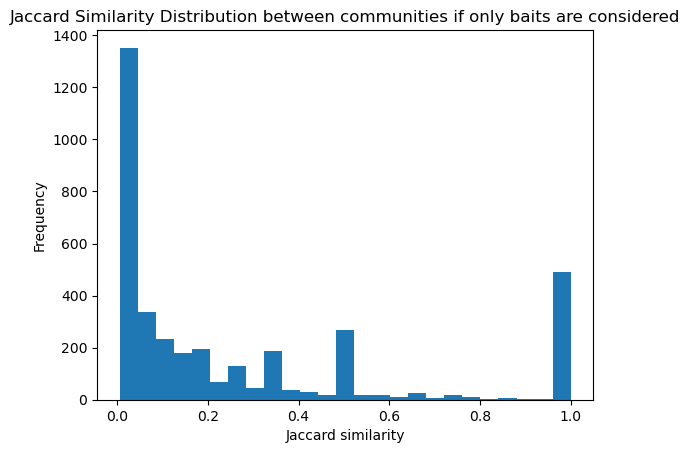

In [133]:
import numpy as np
import matplotlib.pyplot as plt

matrix = top_10_values
# Assuming your 2D matrix is named 'matrix'
non_zero_values = matrix[matrix != 0]

# Plot the histogram
plt.hist(non_zero_values, bins=25)
plt.xlabel('Jaccard similarity')
plt.ylabel('Frequency')
plt.title('Jaccard Similarity Distribution between communities if only baits are considered')
plt.show()

## Baits stay the same
- Do we see interaction strength change?

In [134]:
#### Take communities with a jaccard index of the baits of only 1.0
def findCommunitiesWithJaccardIndexOfOne(sorted_jaccard, partition_1, partition_2, number_of_baits, sample_matrices):
    
    count_table = []

    matching_indices = np.where(sorted_jaccard == 1.0)[0]
    for index in matching_indices:
        community_1 = partition_1[index]
        community_2 = partition_2[top_10_indices[index][0]]

        # get all baits
        community_1_baits = {x for x in community_1 if x <= number_of_baits}
        community_2_baits = {x for x in community_2 if x <= number_of_baits}
        baits = community_1_baits.union(community_2_baits)

        # if index == 3692:
        # ic(baits, index, community_1, community_2)

        # get for each bait from sample A and B the interactions
        for bait_index in baits:
            # matrix_sample_1[bait_index, :]
            # matrix_sample_2[bait_index, :]
            # ic(matrix_sample_1[bait_index, :], matrix_sample_2[bait_index, :])
            try:
                all_OE = np.unique(np.concatenate([intersection_matrices[bait_index, :].nonzero()[1], intersection_matrices[bait_index, :].nonzero()[1]]))
            except:
                ic(bait_index)
                ic(matrices_sample_1[0][bait_index, :])
                ic(matrices_sample_2[0][bait_index, :])
                break
            for interaction_index in all_OE:
                id = str(bait_index) + "_" + str(interaction_index)
                count_table_line = []
                count_table_line.append(id)
                for matrix in matrices_sample_1:
                    count_table_line.append(int(matrix[bait_index, interaction_index]))
                for matrix in matrices_sample_2:
                    count_table_line.append(int(matrix[bait_index, interaction_index]))
                count_table.append(count_table_line)
                # ic(interaction_index)
                # ic(matrix_sample_1[bait_index, interaction_index])

                # ic(matrix_sample_2[bait_index, interaction_index])
        # break
        # create a table to compare the interactions
    
    columns_ids = ['GeneID']
    for i in range(len(matrices_sample_1)):
        columns_ids.append("Sample1_" + str(i))
    for i in range(len(matrices_sample_2)):
        columns_ids.append("Sample2_" + str(i))
    count_table_df = pd.DataFrame(count_table, columns=columns_ids)
    count_table_df = count_table_df.set_index('GeneID')
    return count_table_df



In [135]:
count_table_df = findCommunitiesWithJaccardIndexOfOne(top_10_values, partition_Pinna_E12_5, partition_Pinna_E14_5, sample_matrix_Pinna_E12_5.shape[0], interaction_matrices_sample_Pinna_12_5[:2], interaction_matrices_sample_Pinna_14_5[:2])

ic| bait_index: 6


TypeError: 'hiCMatrix' object is not subscriptable

In [139]:
interaction_matrices_sample_Pinna_12_5[:2][0].matrix

<851636x851636 sparse matrix of type '<class 'numpy.float64'>'
	with 134063 stored elements in Compressed Sparse Row format>

In [75]:
foo

,Sample1,Sample2,Sample3,Sample4
GeneID,,,,
21_2538,0,0,5,5
21_2539,0,0,5,5
21_2739,7,7,0,0
23_3032,8,8,0,0
23_3062,5,5,0,0
...,...,...,...,...
25104_825022,0,0,5,5
25104_825023,6,6,0,0
25104_825081,5,5,0,0


In [76]:
columnData = [['Sample1', 'E12.5', '1'], ['Sample2', 'E12.5', '2'], ['Sample3', 'E14.5', '1'], ['Sample4', 'E14.5', '2']]
columnData_df = pd.DataFrame(columnData, columns = ['Sample', 'Condition', 'Replicate'])
columnData_df = columnData_df.set_index('Sample')

In [66]:
columnData_df

,Condition,Replicate
Sample,,
Sample1,E12.5,1
Sample2,E12.5,2
Sample3,E14.5,1
Sample4,E14.5,2


In [70]:
foo


,Sample1,Sample2
GeneID,,
21_2538,0,5
21_2539,0,5
21_2739,7,0
23_3032,8,0
23_3062,5,0
...,...,...
25104_825022,0,5
25104_825023,6,0
25104_825081,5,0


In [68]:
r_dataframe_column

Condition,Replicate
...,...


In [77]:
import rpy2.robjects as robjects
from rpy2.robjects import pandas2ri
from rpy2.robjects.packages import importr

# Install and import DESeq2
if not importr("DESeq2", robject_translations={"format_pandas_data_frame": False}):
    robjects.r(f'install.packages("DESeq2")')
deseq2 = importr("DESeq2")

# Convert pandas DataFrame to R DataFrame
pandas2ri.activate()
r_dataframe = pandas2ri.DataFrame(foo)
r_dataframe_column = pandas2ri.DataFrame(columnData_df)


# Run DESeq2 analysis
design_formula = "~ Condition"  # Replace 'condition' with your actual condition variable
# dds = DESeq2.DESeqDataSetFromMatrix(countData=counts_r, colData=col_data_r, design=robjects.Formula(design_formula))
dds = deseq2.DESeqDataSetFromMatrix(countData=r_dataframe, colData=r_dataframe_column, design=robjects.Formula(design_formula))
dds = deseq2.DESeq(dds)

# Get differential expression results
results = deseq2.results(dds)

# Convert results to pandas DataFrame
results_dataframe = pandas2ri.ri2py(results)

# Print the results
print(results_dataframe)






  all gene-wise dispersion estimates are within 2 orders of magnitude
  from the minimum value, and so the standard curve fitting techniques will not work.
  One can instead use the gene-wise estimates as final estimates:
  dds <- estimateDispersionsGeneEst(dds)
  dispersions(dds) <- mcols(dds)$dispGeneEst
  ...then continue with testing using nbinomWaldTest or nbinomLRT


 



RRuntimeError: Error in estimateDispersionsFit(object, fitType = fitType, quiet = quiet) : 
  all gene-wise dispersion estimates are within 2 orders of magnitude
  from the minimum value, and so the standard curve fitting techniques will not work.
  One can instead use the gene-wise estimates as final estimates:
  dds <- estimateDispersionsGeneEst(dds)
  dispersions(dds) <- mcols(dds)$dispGeneEst
  ...then continue with testing using nbinomWaldTest or nbinomLRT


In [77]:
top_10_indices[index][0]

3599

In [69]:
matching_entries

array([[   1, 3599, 1195, 1207, 1206],
       [   2, 3599, 1195, 1207, 1206],
       [   3, 3599, 1195, 1207, 1206],
       ...,
       [3597, 3599, 1194, 1206, 1205],
       [3598, 1181, 1207, 1206, 1205],
       [3599, 1236, 1206, 1205, 1204]])

In [111]:
# Sort the values per highest row numbers
sorted_values = np.sort(top_10_values, axis=1)[:, ::-1]

# Keep the indices of the rows
sorted_indices = np.argsort(top_10_values, axis=1)[:, ::-1]

# Print the sorted values and indices
print("Sorted values per highest row numbers:")
print(sorted_values)
print("Indices of the rows:")
print(sorted_indices)


Sorted values per highest row numbers:
[[0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 [0.02380952 0.         0.         0.         0.        ]
 ...
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]
 [1.         0.         0.         0.         0.        ]]
Indices of the rows:
[[0 4 3 2 1]
 [0 4 3 2 1]
 [0 4 3 2 1]
 ...
 [0 4 3 2 1]
 [0 4 3 2 1]
 [0 4 3 2 1]]


In [67]:
top_10_values[1295, :]

array([0.76923077, 0.04081633, 0.        , 0.        , 0.        ])

In [68]:
top_10_indices[1295, :]

array([1293, 1401, 3692, 1239, 1237])

In [62]:
top_10_indices[3692, :]

array([3509, 3508, 3692, 1224, 1235])

In [59]:
top_10_values.shape

(3884, 5)

In [39]:
print(communities_E12_5[1295].intersection(communities_E14_5[1293]))
print(len(communities_E12_5[1295].intersection(communities_E14_5[1293])))

print(len(communities_E12_5[1295]))
print(len(communities_E14_5[1293]))


{642560, 642562, 642074, 642075, 642076, 642077, 642078, 642079, 642080, 642081, 642082, 642083, 642084, 642085, 642086, 642087, 642088, 642089, 642602, 642606, 642096, 8761, 8765, 8766, 8767, 8768, 8769, 8771, 8773, 8774, 8775, 8776, 642646, 642649, 642650, 642651, 642653, 642671, 642672, 642198, 642199, 642309, 642310, 642351, 642352, 642353, 642355, 642356, 642358, 642359, 642360, 642361, 642411, 642413, 642426, 642436, 642437, 641958, 641960, 641961, 8133, 8137, 8138, 8139, 8140, 8142, 8143, 8144, 642001, 642002, 642003, 8145, 642013, 642549, 642551, 642552, 642554, 642555, 642559}
79
155
116


In [37]:
for i in range(len(communities_E12_5)):
    if 8767 in communities_E12_5[i]:
        print(i)
        break
for i in range(len(communities_E14_5)):
    if 8767 in communities_E14_5[i]:
        print(i)
        break

1295
1293


In [36]:
bait_list_Pinna_E12_5[8767]

Name    Hoxa2_1
Name: 8767, dtype: object

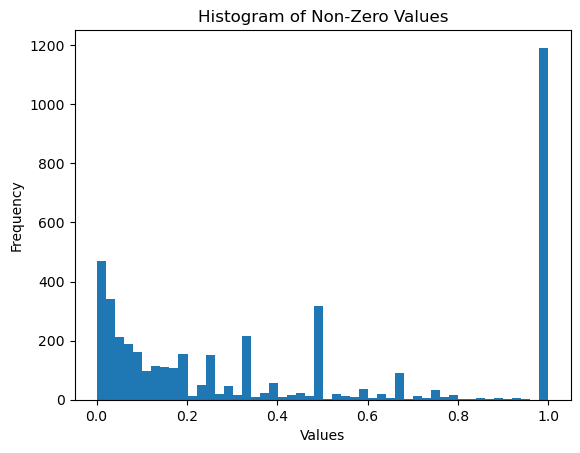

In [133]:
non_zero_values

array([0.02380952, 0.02380952, 0.02380952, ..., 1.        , 1.        ,
       1.        ])

In [119]:
import multiprocessing
distance_matrix = np.full((len(communities_E12_5), len(communities_E14_5)), -1)
subgraphs_E12_5 = []
subgraphs_E14_5 = []

def compute_distance(i, j):
    subgraph_E12_5 = G_Pinna_E12_5.subgraph(communities_E12_5[i])
    subgraph_E14_5 = G_Pinna_E14_5.subgraph(communities_E14_5[j])
    if nx.is_isomorphic(subgraph_E12_5, subgraph_E14_5):
        distance_matrix[i, j] = 0
    else:
        distance_matrix[i, j] = nx.optimize_graph_edit_distance(subgraph_E12_5, subgraph_E14_5)

pool = multiprocessing.Pool()
for i in range(len(communities_E12_5)):
    for j in range(len(communities_E14_5)):
        pool.apply_async(compute_distance, args=(i, j))

pool.close()
pool.join()


KeyboardInterrupt: 

: 

In [118]:
distance_matrix

array([[-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       ...,
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1],
       [-1, -1, -1, ..., -1, -1, -1]])

In [102]:
max(partition_Pinna_E12_5.values())

3887

In [103]:
len(community_E14_5)

3693

In [104]:
max(partition_Pinna_E14_5.values())

3691